![Banner](../images/03_08_banner_spatial_analysis_capstone.png)

# Habitat Suitability and Landscape Connectivity for the Forest Musk Deer

This is Capstone 5 of the spatial analysis module (Part 7). It maps habitat for the forest musk deer (*Moschus berezovskii*) in the Huanglong Mountains of Shaanxi and asks which patches are large enough, and still connected, for the animals to move between them. The analysis follows Zheng et al. (2026) with a knowledge-driven model, a presence-background ensemble, and least-cost and circuit connectivity.

**Data:** 177 coarsened occurrence records and eight predictors in `data/Data_and_Code_Forest_Musk_Deer` (Dryad, doi:10.5061/dryad.qbzkh1902).

**Study area:** Huanglong Mountains, about 7,293 km².

**Library:** `geolattice.spatial_analysis`


## Overview

| Stage | Question | Main tools |
|---|---|---|
| **Prepare** | Are the layers on one metric grid? | `reproject_raster`, `warp` |
| **Scale check** | What can coarsened occurrence records support? | block summaries |
| **Model A: multi-criteria** | Which cells meet the published habitat requirements? | `large`, `small`, `gaussian`, `weighted_linear_combination`, `score_contributions` |
| **Model B: machine learning** | Where does the landscape match the places the species was recorded? | logistic GLM, MaxEnt-style model, classification tree, random forest, gradient boosting; spatial cross-validation; AUC-weighted ensemble |
| **Combine** | Where are both local habitat and landscape context suitable? | geometric mean, lowest-presence threshold, patch filter |
| **Uncertainty** | How sensitive is Model A to its weights? | `monte_carlo_weights` |
| **Connect** | Which patches are linked, and at what cost? | resistance function, cost distance, least-cost paths |
| **Bottlenecks** | Where does movement concentrate, and does it cross roads? | circuit theory (current density) |

### What this notebook reuses

| Topic | Notebook |
|---|---|
| Raster analysis basics | [`03_01_03_raster_analysis.ipynb`](../03_01_foundation/03_01_03_raster_analysis.ipynb) |
| Fuzzy membership and weighted overlay | [`03_04_02_00_fuzzy_logic_foundations.ipynb`](../03_04_multi_criteria_suitability_analysis/03_04_02_00_fuzzy_logic_foundations.ipynb), [`03_04_01_03_weighted_suitability.ipynb`](../03_04_multi_criteria_suitability_analysis/03_04_01_03_weighted_suitability.ipynb) |
| Weight uncertainty | [`03_04_03_sensitivity_uncertainty.ipynb`](../03_04_multi_criteria_suitability_analysis/03_04_03_sensitivity_uncertainty.ipynb) |
| Network thinking | [`03_05_00_introduction_network_analysis.ipynb`](../03_05_network_analysis/03_05_00_introduction_network_analysis.ipynb) |

## Table of Contents

1. [Setup](#setup)
2. [Problem statement, study area and data](#problem-statement-study-area-and-data)
3. [Data preparation](#data-preparation)
4. [The scale problem: what coarsened records can support](#the-scale-problem-what-coarsened-records-can-support)
5. [Model A: knowledge-driven habitat suitability](#model-a-knowledge-driven-habitat-suitability)
6. [Model B: presence-background ensemble](#model-b-presence-background-ensemble)
7. [Combining the two models](#combining-the-two-models)
8. [Primary habitat patches](#primary-habitat-patches)
9. [Weight uncertainty in Model A](#weight-uncertainty-in-model-a)
10. [Resistance surface](#resistance-surface)
11. [Least-cost corridors](#least-cost-corridors)
12. [Pinch points with circuit theory](#pinch-points-with-circuit-theory)
13. [Protected-area gap analysis (optional external data)](#protected-area-gap-analysis-optional-external-data)
14. [Outputs](#outputs)
15. [Comparison with the published study, and limitations](#comparison-with-the-published-study-and-limitations)
16. [Where to go next](#where-to-go-next)

## Setup

**Installation.** This notebook needs installation option 2 (core plus spatial analysis): `pip install "geolattice[analysis]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

# Standard library imports.
import sys  # make the capstone helper module importable
import time  # report how long the heavier steps take
import warnings  # silence harmless runtime warnings from empty slices
from pathlib import Path  # filesystem paths

# Third-party numeric / geospatial / plotting stack.
import geopandas as gpd  # patch polygons and outputs
import matplotlib.pyplot as plt  # maps and charts
import numpy as np  # raster arrays
import pandas as pd  # tables
from IPython.display import display  # rich table previews
from pyproj import Transformer  # longitude / latitude -> UTM
from scipy import ndimage  # moving-window summaries and patch labelling
from scipy import sparse  # graph and circuit matrices
from scipy.sparse import csgraph  # cost distance (Dijkstra)
from scipy.sparse.linalg import spsolve  # circuit solves

# Machine learning (scikit-learn).
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import GroupKFold, StratifiedShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, SplineTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

# Shared capstone helpers live next to this notebook.
sys.path.insert(0, str(Path.cwd()))
import data_processing as dp  # paths and raster I/O

import geolattice

ROOT = Path(geolattice.__file__).resolve().parents[1]
if not (ROOT / "Data").is_dir():
    ROOT = dp.find_repo_root()

# GeoLattice tools.
from geolattice.raster import polygonize, reproject_raster, warp, write_raster_data
from geolattice.spatial_analysis import (
    gaussian,  # bell-shaped membership around an optimum
    large,  # sigmoid membership, large values -> 1
    linear,  # linear ramp membership
    monte_carlo_weights,  # Dirichlet weight uncertainty
    score_contributions,  # per-criterion weighted contributions
    small,  # sigmoid membership, small values -> 1
    weighted_linear_combination,  # weighted linear combination
)
from geolattice.viz import apply_map_style

apply_map_style()
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)  # scikit-learn API deprecation notices
warnings.filterwarnings("ignore", message=".*penalty.*")  # same, for the L1 logistic model
pd.set_option("display.precision", 3)
RNG = np.random.default_rng(2026)  # one seed for every random step

# Inputs and outputs.
SRC = ROOT / "Data" / "03_spatial_analysis" / "Data_and_Code_Forest_Musk_Deer"
OUT = dp.capstone_dir(ROOT, "musk_deer")
print(f"Inputs:  {SRC}")
print(f"Outputs: {OUT}")

Inputs:  /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/Data_and_Code_Forest_Musk_Deer
Outputs: /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/capstone_spatial_analysis/musk_deer


## Problem statement, study area and data

**Study area.** The Huanglong Mountains, south-east of Yan'an, Shaanxi Province (about 109.6°E to 110.6°E, 35.3°N to 36.4°N; 7,293 km²). The climate is temperate continental monsoon, annual precipitation is 400 to 600 mm and forest covers at least 65 percent of the land. Three nature reserves lie inside the area; two were designated for the brown eared pheasant, one for musk deer.

**Question.** Where is habitat for the forest musk deer, which patches are large enough to support home ranges, and where is movement between patches most constrained?

**Data** (Dryad, doi:10.5061/dryad.qbzkh1902, CC0):

| File | Content |
|---|---|
| `spe_example.csv` | 177 occurrence records from DNA-confirmed faecal samples (2016-2017, 2024), after a 120 m spatial filter |
| `current/*.asc` | The eight predictors retained by the authors, each already at its optimal neighbourhood scale, about 30 m cells |

| Predictor | Meaning | Paper's reported response |
|---|---|---|
| `Slope` | Mean slope (degrees) | Strongest driver (56.2 % contribution); prefers > 22° |
| `Bio12` | Annual precipitation (mm) | 19.1 %; peak near 462 mm |
| `Bio5` | Maximum temperature of the warmest month (°C) | 12.8 %; rises as it falls below 27 °C |
| `Landcover` | Land-cover class (1-11) | Coniferous forest (5) best, then broadleaf forest (4) |
| `Dis_resident` | Distance to settlements (m) | Prefers > 5,000 m |
| `Dis_river` | Distance to rivers (m) | Prefers proximity |
| `Dis_road` | Distance to roads (m) | Minor |
| `Aspect` | Transformed aspect (0-1) | Minor |

> **A property of these data that shapes the whole analysis.** Because the species is poached for musk, the authors coarsened every published coordinate to **0.1 decimal degrees**, roughly 9 km east-west by 11 km north-south here. The predictors, in contrast, are 30 m grids. Section 4 shows what that means and how the two models below are designed around it. The results will therefore **not** reproduce the published maps cell for cell, and they should not be read as locating animals.

In [2]:
# Occurrence records.
occ = pd.read_csv(SRC / "spe_example.csv")
print(f"Records: {len(occ)}")
sites = occ.groupby(["longitude", "latitude"]).size().rename("records").reset_index()
print(f"Distinct coordinate pairs after coarsening: {len(sites)}")
display(sites.sort_values("records", ascending=False).head(8))

Records: 177
Distinct coordinate pairs after coarsening: 23


,longitude,latitude,records
17,110.3,35.9,51
13,110.2,35.9,30
15,110.3,35.7,15
11,110.2,35.7,13
21,110.4,35.9,12
7,110.1,35.6,9
10,110.2,35.6,7
19,110.4,35.7,5


The 177 records collapse to **23 distinct 0.1° grid centres**. Two thirds of the records sit on just four centres, which mostly reflects where the transects were walked. One centre, 110.3°E 35.1°N, lies south of the predictor extent and is dropped below.

## Data preparation

The ASCII grids carry no projection file. Their header (cell size 0.000303°) shows geographic coordinates, so they are read as WGS 84, then projected to **UTM zone 49N** (the projection used in the paper) on a **90 m** grid. A 90 m cell keeps the fine-scale detail the multi-criteria model needs while keeping the notebook fast.

- Continuous layers use bilinear resampling.
- `Landcover` uses the majority (mode) of the 30 m cells.
- A road mask is built on the original grid (`Dis_road == 0`) and kept wherever any 30 m road cell falls in the 90 m cell, so thin roads are not lost.

In [3]:
CRS_UTM = "EPSG:32649"  # WGS 84 / UTM zone 49N
CELL = 90.0  # analysis cell size (m)
PREDICTORS = ["Slope", "Bio12", "Bio5", "Landcover", "Dis_resident", "Dis_river", "Dis_road", "Aspect"]

t0 = time.time()
GRID = {}  # name -> path of the 90 m UTM raster
for name in PREDICTORS:
    dst = OUT / f"{name.lower()}_90m.tif"
    if not dst.exists():
        reproject_raster(
            SRC / "current" / f"{name}.asc", dst, CRS_UTM, src_crs="EPSG:4326",
            resample="mode" if name == "Landcover" else "bilinear", resolution=CELL, overwrite=True,
        )
    GRID[name] = dst

# Road mask on the source grid, then "max" so any road cell marks the 90 m cell.
ROADS = OUT / "roads_90m.tif"
if not ROADS.exists():
    from osgeo import gdal

    src = gdal.Open(str(SRC / "current" / "Dis_road.asc"))
    a = src.GetRasterBand(1).ReadAsArray()
    road30 = OUT / "roads_30m_src.tif"
    write_raster_data(road30, np.where(a == -9999, 255, (a == 0)).astype("uint8"), crs="EPSG:4326",
                      geotransform=src.GetGeoTransform(), nodata=255, overwrite=True)
    src = None
    reproject_raster(road30, ROADS, CRS_UTM, resample="max", resolution=CELL, overwrite=True)
    road30.unlink()
print(f"Reprojection done in {time.time() - t0:.0f} s")

# Load everything on the common grid.
layers = {name: dp.read_band(path)[0] for name, path in GRID.items()}
_, GT, _ = dp.read_band(GRID["Slope"])
EXTENT = dp.extent_of(GRID["Slope"])
valid = np.all([np.isfinite(a) for a in layers.values()], axis=0)
roads = (dp.read_band(ROADS)[0] == 1) & valid
CELL_HA = CELL * CELL / 1e4
print(f"Grid: {valid.shape[1]} x {valid.shape[0]} cells, study area {valid.sum() * CELL_HA / 100:,.0f} km2")
print(f"Road cells: {roads.sum():,} ({roads.mean() / valid.mean():.1%} of the area)")

Reprojection done in 0 s
Grid: 976 x 1351 cells, study area 7,291 km2
Road cells: 39,023 (4.3% of the area)


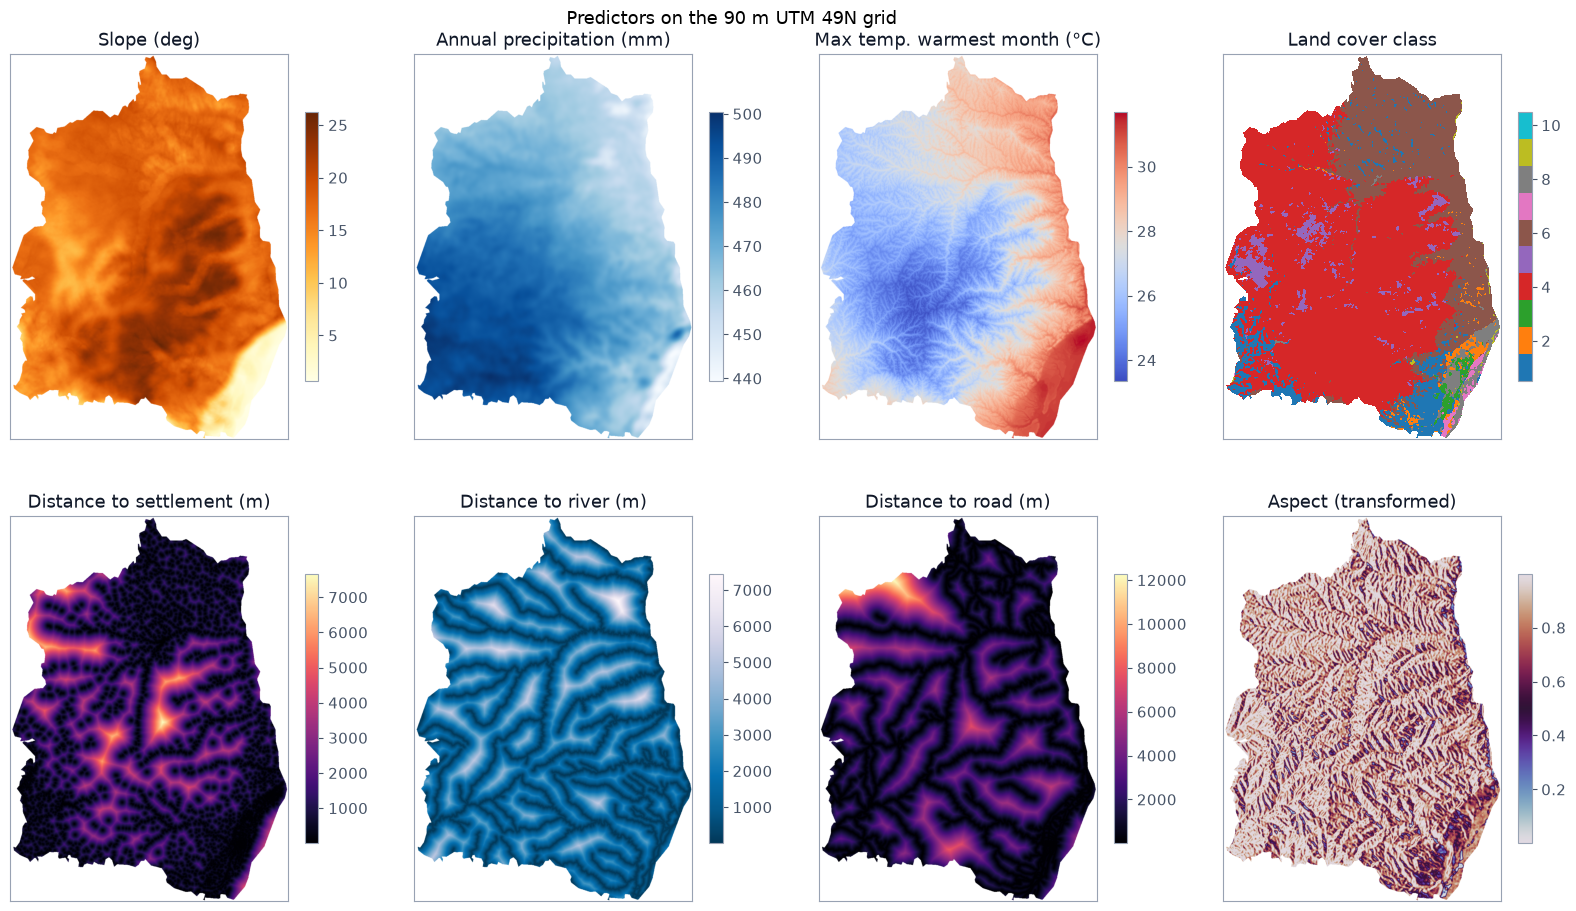

,% of area
broadleaf forest,58.703
grassland,25.365
rainfed cropland,6.800
needle-leaved forest,4.244
flooded flat,2.143
herbaceous cropland,1.203
irrigated cropland,0.777
marsh,0.567
impervious,0.197


In [4]:
# Map the eight predictors.
titles = {"Slope": "Slope (deg)", "Bio12": "Annual precipitation (mm)", "Bio5": "Max temp. warmest month (°C)",
          "Landcover": "Land cover class", "Dis_resident": "Distance to settlement (m)",
          "Dis_river": "Distance to river (m)", "Dis_road": "Distance to road (m)", "Aspect": "Aspect (transformed)"}
cmaps = {"Slope": "YlOrBr", "Bio12": "Blues", "Bio5": "coolwarm", "Landcover": "tab10", "Dis_resident": "magma",
         "Dis_river": "PuBu_r", "Dis_road": "magma", "Aspect": "twilight"}
fig, axes = plt.subplots(2, 4, figsize=(20, 11))
for ax, name in zip(axes.ravel(), PREDICTORS):
    arr = np.where(valid, layers[name], np.nan)
    kw = dict(vmin=0.5, vmax=10.5, interpolation="nearest") if name == "Landcover" else {}
    im = ax.imshow(arr, cmap=cmaps[name], extent=EXTENT, **kw)
    ax.set_title(titles[name])
    ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(im, ax=ax, fraction=0.04)
plt.suptitle("Predictors on the 90 m UTM 49N grid", y=0.92)
plt.show()

# Land-cover composition.
LC_NAMES = {1: "rainfed cropland", 2: "herbaceous cropland", 3: "irrigated cropland", 4: "broadleaf forest",
            5: "needle-leaved forest", 6: "grassland", 7: "marsh", 8: "flooded flat", 9: "impervious",
            10: "bare", 11: "water"}
lc = layers["Landcover"]
share = pd.Series({LC_NAMES[int(k)]: 100 * np.mean(lc[valid] == k) for k in np.unique(lc[valid])}, name="% of area")
display(share.sort_values(ascending=False).to_frame())

Two things stand out. Slope is smooth, with a maximum of 26°: the authors supplied it as a neighbourhood mean at their optimal scale (a 1,920 m radius), not as cell slope. And broadleaf forest dominates, while needle-leaved forest, the class the species prefers, covers only about 4 percent.

## The scale problem: what coarsened records can support

A presence-background model compares conditions at occurrence points with conditions across the study area. That only works if the occurrence point and the predictor describe the same place. Here each record is known only to lie somewhere in a 0.1° block, while a predictor cell is 90 m wide.

Two quantities make the problem concrete for slope, the dominant driver:

- the value **at the grid centre**, which is what a naive model would use;
- the **block mean** over the 0.1° block around the centre, which is what the record can honestly represent.

In [5]:
to_utm = Transformer.from_crs("EPSG:4326", CRS_UTM, always_xy=True)
sites["x"], sites["y"] = to_utm.transform(sites.longitude.values, sites.latitude.values)
rc = [dp.xy_to_rowcol(x, y, GT) for x, y in zip(sites.x, sites.y)]
sites["row"] = [r for r, _ in rc]
sites["col"] = [c for _, c in rc]
inside = (sites.row.between(0, valid.shape[0] - 1)) & (sites.col.between(0, valid.shape[1] - 1))
print("Dropped (outside the predictor extent):", sites.loc[~inside, ["longitude", "latitude"]].values.tolist())
sites = sites[inside].reset_index(drop=True)

# A centre that falls on a masked cell (outside the study-area outline) moves to the nearest valid cell.
near_r, near_c = ndimage.distance_transform_edt(~valid, return_distances=False, return_indices=True)
moved = ~valid[sites.row, sites.col]
sites["row"], sites["col"] = near_r[sites.row, sites.col], near_c[sites.row, sites.col]
print(f"Centres moved onto the study area: {int(moved.sum())}")

# Block size in cells: 0.1 degree of longitude and of latitude at the study-area centre.
LAT0 = 35.85
BLOCK_X = int(round(0.1 * 111_320 * np.cos(np.radians(LAT0)) / CELL))  # ~ 9.0 km
BLOCK_Y = int(round(0.1 * 110_950 / CELL))  # ~ 11.1 km
print(f"0.1-degree block = {BLOCK_X} x {BLOCK_Y} cells ({BLOCK_X * CELL / 1000:.1f} km x {BLOCK_Y * CELL / 1000:.1f} km)")


def block_mean(arr, mask, size=(BLOCK_Y, BLOCK_X)):
    """Moving-window mean over valid cells only (NaN outside ``mask``)."""
    a = np.where(mask, arr, 0.0)
    num = ndimage.uniform_filter(a, size=size, mode="constant")
    den = ndimage.uniform_filter(mask.astype(float), size=size, mode="constant")
    return np.where(mask & (den > 0), num / np.maximum(den, 1e-12), np.nan)


slope = layers["Slope"]
slope_block = block_mean(slope, valid)
steep_block = block_mean((slope > 22).astype(float), valid)
sites["slope_at_centre"] = [slope[r, c] for r, c in zip(sites.row, sites.col)]
sites["block_mean_slope"] = [slope_block[r, c] for r, c in zip(sites.row, sites.col)]
sites["block_share_gt22"] = [steep_block[r, c] for r, c in zip(sites.row, sites.col)]

summary = pd.DataFrame(
    {
        "occurrence blocks (mean)": sites[["slope_at_centre", "block_mean_slope", "block_share_gt22"]].mean(),
        "whole study area": [np.nanmean(slope[valid]), np.nanmean(slope[valid]), np.mean(slope[valid] > 22)],
    }
)
display(summary)

Dropped (outside the predictor extent): [[110.3, 35.1]]
Centres moved onto the study area: 1
0.1-degree block = 100 x 123 cells (9.0 km x 11.1 km)


,occurrence blocks (mean),whole study area
slope_at_centre,20.518,17.502
block_mean_slope,20.151,17.502
block_share_gt22,0.331,0.128


**What this shows.**

- Around the occurrence blocks, mean slope is about 3° above the landscape average and the share of land steeper than 22° is more than twice as high. The habitat signal survives at block scale.
- The centre cell itself is an arbitrary point. It has no ecological link to where a sample was collected, so treating centres as exact locations would train a model on noise at 90 m.

**Design consequence.** The notebook uses each kind of information at the scale it supports:

| Model | Information | Scale | Role |
|---|---|---|---|
| **A, multi-criteria** | The species' habitat requirements as published | 90 m cells | Where local conditions are suitable |
| **B, machine learning** | The 22 occurrence blocks against the background | 0.1° block summaries, mapped on a 270 m grid | Where the surrounding landscape resembles occupied blocks |

The final map requires both. A cell that meets the habitat requirements but lies in a landscape unlike any occupied block, or the reverse, is not treated as primary habitat.

## Model A: knowledge-driven habitat suitability

Each predictor is converted to a **membership** between 0 and 1 that follows the response the paper reports (Section 3.2 and Figure 2 of Zheng et al. 2026):

| Criterion | Membership | Parameters | Reason |
|---|---|---|---|
| Slope | `large` (sigmoid) | midpoint 20°, spread 12 | Steep terrain preferred, above 22° in the paper |
| Annual precipitation | `gaussian` | optimum 462 mm | Peak of the response curve |
| Max. warm-month temperature | `small` (sigmoid) | midpoint 27 °C, spread 30 | Suitability rises below 27 °C |
| Land cover | class scores | needle-leaved 1.0, broadleaf 0.8, grassland 0.3, croplands 0.1, built-up 0 | Ranking of classes in the response curve |
| Distance to settlement | `linear` | 0 at 0 m, 1 at 5,000 m | Preference for > 5 km |
| Distance to river | `linear` (decreasing) | 1 at 500 m, 0 at 4,000 m | Preference for proximity |
| Distance to road | `linear` | 0 at 0 m, 1 at 1,000 m | Minor avoidance |

Aspect is left out: its transformation is not documented in the data release, so its direction cannot be interpreted.

**Weights** follow the paper's relative contributions where they are reported: slope 56.2, precipitation 19.1, temperature 12.8. The paper gives only an upper bound (< 5 % each) for the rest; the remaining 11.9 points are split here as land cover 4.5, settlements 3.4, rivers 2.5 and roads 1.5. That split is a modelling choice, and Section 9 tests how much it matters.

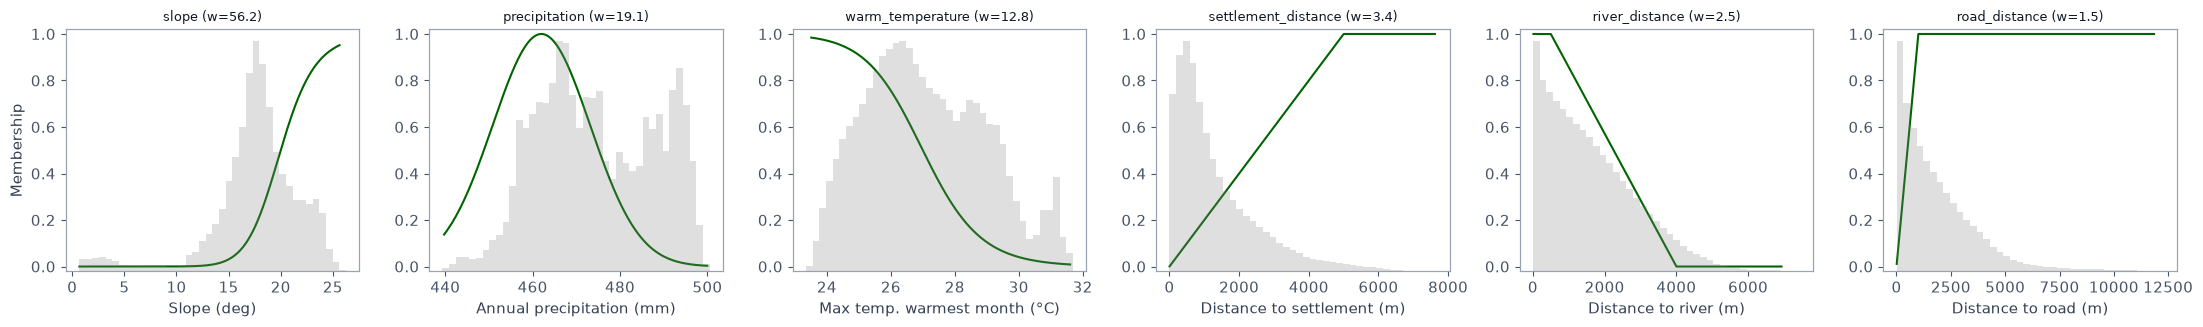

In [6]:
# Membership functions (GeoLattice) applied to every 90 m cell.
lc_scores = {1: 0.1, 2: 0.1, 3: 0.1, 4: 0.8, 5: 1.0, 6: 0.3, 7: 0.1, 8: 0.05, 9: 0.0, 10: 0.0, 11: 0.0}
lc_member = np.full(lc.shape, np.nan)
for k, v in lc_scores.items():
    lc_member[lc == k] = v

members = {
    "slope": large(np.maximum(slope, 1e-6), midpoint=20.0, spread=12.0),
    "precipitation": gaussian(layers["Bio12"], midpoint=462.0, spread=0.004),
    "warm_temperature": small(layers["Bio5"], midpoint=27.0, spread=30.0),
    "land_cover": lc_member,
    "settlement_distance": linear(layers["Dis_resident"], 0.0, 5000.0),
    "river_distance": linear(layers["Dis_river"], 4000.0, 500.0),
    "road_distance": linear(layers["Dis_road"], 0.0, 1000.0),
}
members = {k: np.where(valid, np.clip(np.asarray(v, float), 0, 1), np.nan) for k, v in members.items()}

WEIGHTS_A = {"slope": 56.2, "precipitation": 19.1, "warm_temperature": 12.8, "land_cover": 4.5,
             "settlement_distance": 3.4, "river_distance": 2.5, "road_distance": 1.5}

# Plot the membership curves over the observed range of each variable.
curve_vars = [("slope", slope, "Slope (deg)"), ("precipitation", layers["Bio12"], "Annual precipitation (mm)"),
              ("warm_temperature", layers["Bio5"], "Max temp. warmest month (°C)"),
              ("settlement_distance", layers["Dis_resident"], "Distance to settlement (m)"),
              ("river_distance", layers["Dis_river"], "Distance to river (m)"),
              ("road_distance", layers["Dis_road"], "Distance to road (m)")]
fig, axes = plt.subplots(1, 6, figsize=(22, 3.4))
for ax, (key, raw, label) in zip(axes, curve_vars):
    x, y = raw[valid], members[key][valid]
    idx = RNG.choice(x.size, 4000, replace=False)
    order = np.argsort(x[idx])
    ax.plot(x[idx][order], y[idx][order], color="darkgreen")
    ax2 = ax.twinx()
    ax2.hist(x, bins=40, color="grey", alpha=0.25)
    ax2.set_yticks([])
    ax.set_ylim(-0.02, 1.02)
    ax.set_xlabel(label)
    ax.set_title(f"{key} (w={WEIGHTS_A[key]})", fontsize=9)
axes[0].set_ylabel("Membership")
plt.tight_layout()
plt.show()

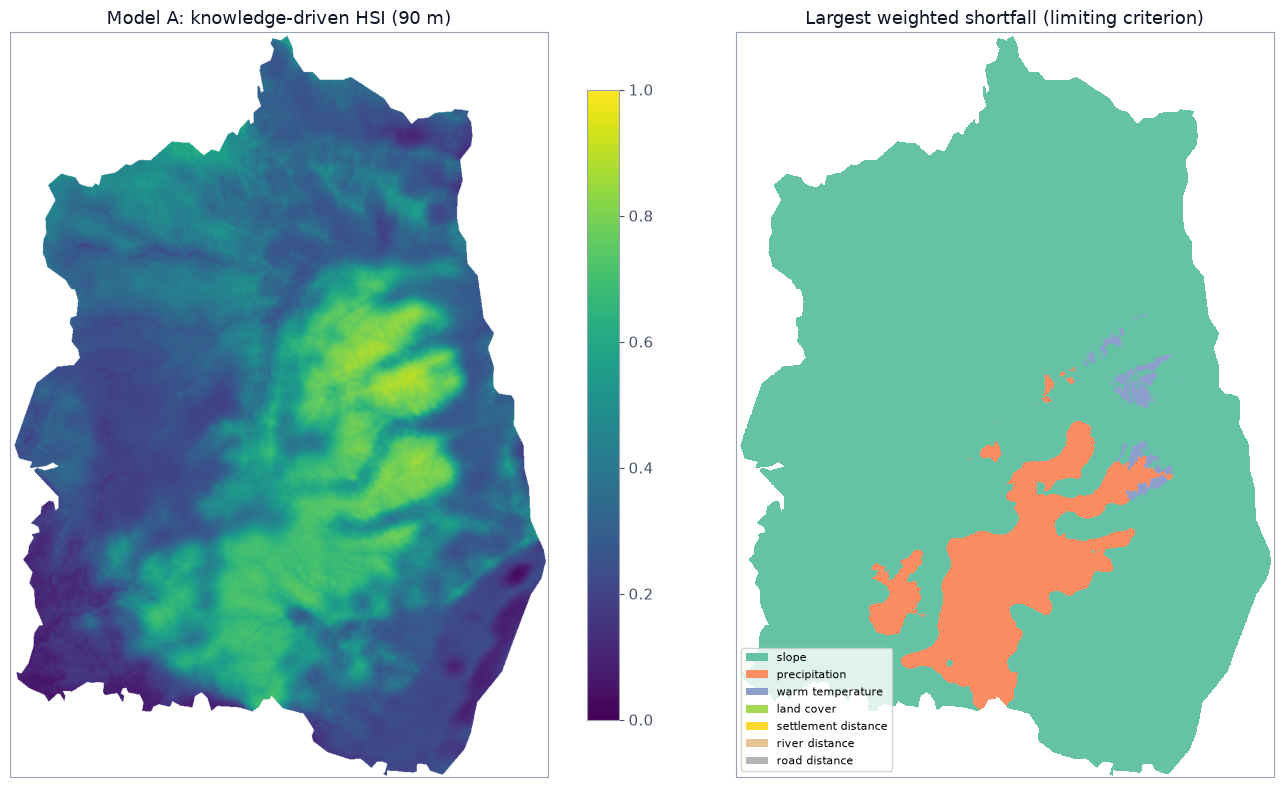

,% of area where limiting
slope,88.843
precipitation,10.298
warm temperature,0.860
land cover,0.000
settlement distance,0.000
river distance,0.000
road distance,0.000


In [7]:
# Weighted linear combination (weights are normalised to sum to 1).
stack_A = {k: np.nan_to_num(v) for k, v in members.items()}
hsi_A = np.where(valid, weighted_linear_combination(stack_A, WEIGHTS_A), np.nan)

# Which criterion contributes most in each cell?
contrib = score_contributions(stack_A, WEIGHTS_A)
names_A = list(contrib)
w_norm = np.array([WEIGHTS_A[k] for k in names_A]) / sum(WEIGHTS_A.values())
# Shortfall = weight x (1 - membership): the criterion that costs each cell most.
shortfall = np.stack([w * (1 - stack_A[k]) for w, k in zip(w_norm, names_A)])
limiting = np.where(valid, np.argmax(shortfall, axis=0), -1)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
im = axes[0].imshow(hsi_A, cmap="viridis", extent=EXTENT, vmin=0, vmax=1)
axes[0].set_title("Model A: knowledge-driven HSI (90 m)")
plt.colorbar(im, ax=axes[0], fraction=0.04)
cm = plt.get_cmap("Set2", len(names_A))
axes[1].imshow(np.where(valid, limiting, np.nan), cmap=cm, extent=EXTENT, vmin=-0.5, vmax=len(names_A) - 0.5,
               interpolation="nearest")
handles = [plt.Rectangle((0, 0), 1, 1, fc=cm(i)) for i in range(len(names_A))]
axes[1].legend(handles, [n.replace("_", " ") for n in names_A], loc="lower left", fontsize=8)
axes[1].set_title("Largest weighted shortfall (limiting criterion)")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

lim_share = pd.Series({names_A[i].replace("_", " "): 100 * np.mean(limiting[valid] == i) for i in range(len(names_A))},
                      name="% of area where limiting")
display(lim_share.sort_values(ascending=False).to_frame())

**Reading Model A.** Because slope carries more than half the weight, the map follows the mountain blocks: high scores along the steep central ranges, low scores on the loess plateau edges and in the valleys. Across almost 90 percent of the area the limiting criterion is slope. Precipitation limits a block in the south-centre where annual rainfall rises above the 462 mm optimum, and warm-month temperature limits small areas in the north-east.

**Checking Model A against the records at the scale they support.** Model A used no occurrence data, so it can be tested on them: if it is right, the 0.1° blocks with records should have higher mean HSI than the rest of the landscape.

In [8]:
hsi_A_block = block_mean(np.nan_to_num(hsi_A), valid)
pres_vals = np.array([hsi_A_block[r, c] for r, c in zip(sites.row, sites.col)])
# Compare with every valid cell's block mean (a block centred on each cell).
bg_vals = hsi_A_block[valid][RNG.choice(valid.sum(), 20000, replace=False)]
auc_A_block = roc_auc_score(np.r_[np.ones(pres_vals.size), np.zeros(bg_vals.size)], np.r_[pres_vals, bg_vals])
print(f"Block-scale AUC of Model A against the 22 occurrence blocks: {auc_A_block:.2f}")

Block-scale AUC of Model A against the 22 occurrence blocks: 0.76


An AUC well above 0.5 means the published habitat requirements, applied without any occurrence data, already rank occupied blocks above the background. That is independent support for Model A, at the only scale the records allow.

## Model B: presence-background ensemble

### Block-scale predictors

Every predictor is summarised over a 0.1° moving block, the precision of the records. Land cover becomes two shares (needle-leaved forest; all forest), and slope gets a second summary, the share of land steeper than 22°. The block summaries are computed on the 90 m grid and sampled on a **270 m** grid, which is ample for surfaces this smooth.

Block summaries in 0 s; 270 m grid 325 x 450, 99,997 cells


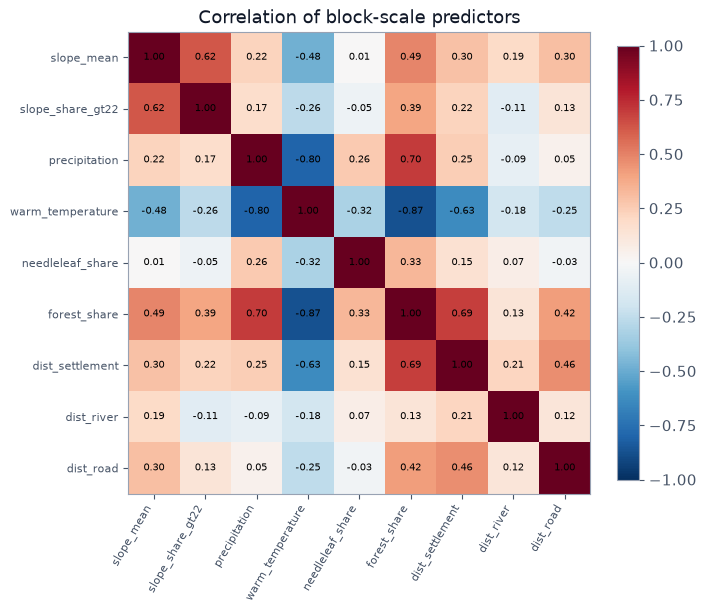

,VIF
slope_mean,2.767
slope_share_gt22,2.137
precipitation,6.463
warm_temperature,11.252
needleleaf_share,1.288
forest_share,7.348
dist_settlement,3.666
dist_river,1.328
dist_road,1.595


In [9]:
AGG = 3  # 90 m -> 270 m
CELL_B = CELL * AGG


def coarsen(arr, how="mean"):
    """Aggregate a 90 m array to 270 m blocks of AGG x AGG cells."""
    r, c = (arr.shape[0] // AGG) * AGG, (arr.shape[1] // AGG) * AGG
    blocks = arr[:r, :c].reshape(r // AGG, AGG, c // AGG, AGG)
    return np.nanmean(blocks, axis=(1, 3)) if how == "mean" else np.nanmax(blocks, axis=(1, 3))


feature_src = {
    "slope_mean": slope,
    "slope_share_gt22": (slope > 22).astype(float),
    "precipitation": layers["Bio12"],
    "warm_temperature": layers["Bio5"],
    "needleleaf_share": (lc == 5).astype(float),
    "forest_share": np.isin(lc, [4, 5]).astype(float),
    "dist_settlement": layers["Dis_resident"],
    "dist_river": layers["Dis_river"],
    "dist_road": layers["Dis_road"],
}
t0 = time.time()
feat270 = {k: coarsen(block_mean(v, valid)) for k, v in feature_src.items()}
valid270 = coarsen(valid.astype(float)) >= 0.5
print(f"Block summaries in {time.time() - t0:.0f} s; 270 m grid {valid270.shape[1]} x {valid270.shape[0]}, "
      f"{valid270.sum():,} cells")

# Collinearity screen: correlations and variance inflation factors on the study area.
F = pd.DataFrame({k: v[valid270] for k, v in feat270.items()}).dropna()


def vif(df):
    out = {}
    for col in df.columns:
        X = df.drop(columns=col).values
        X = np.column_stack([np.ones(len(X)), X])
        beta, *_ = np.linalg.lstsq(X, df[col].values, rcond=None)
        resid = df[col].values - X @ beta
        r2 = 1 - resid.var() / df[col].values.var()
        out[col] = 1 / max(1 - r2, 1e-9)
    return pd.Series(out, name="VIF")


corr = F.corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, ax=ax, fraction=0.04)
ax.set_title("Correlation of block-scale predictors")
plt.show()
display(vif(F).to_frame())

At block scale, warm-month temperature has the highest VIF: it follows elevation, as precipitation and forest cover do. Following the paper's rule (VIF < 5, priority to ecologically direct variables), the cell below drops variables one at a time, highest VIF first, while protecting slope share, temperature and precipitation, the three drivers the paper retained despite their correlation.

In [10]:
protected = {"slope_share_gt22", "warm_temperature", "precipitation"}
keep = list(F.columns)
while True:
    v = vif(F[keep])
    candidates = v.drop(labels=[k for k in protected if k in v.index]).sort_values(ascending=False)
    if candidates.empty or candidates.iloc[0] < 5 or len(keep) <= 4:
        break
    keep.remove(candidates.index[0])
FEATURES = keep
print("Retained predictors:", FEATURES)
display(vif(F[FEATURES]).to_frame())

Retained predictors: ['slope_mean', 'slope_share_gt22', 'precipitation', 'warm_temperature', 'needleleaf_share', 'dist_settlement', 'dist_river', 'dist_road']


,VIF
slope_mean,2.760
slope_share_gt22,1.922
precipitation,5.743
warm_temperature,10.596
needleleaf_share,1.172
dist_settlement,3.116
dist_river,1.323
dist_road,1.385


Only the total forest share is dropped. Temperature and precipitation stay above the threshold and are kept anyway, as the authors kept Bio5 and Bio12 (r = 0.77): their coefficients in the GLM should not be interpreted one at a time, but the tree-based members and the ensemble prediction are not harmed by the overlap.

### Presences and background

- **Presences:** the 22 block centres inside the area, one per block. Repeated records at a centre do not add information about habitat, only about survey effort, so they are not used as weights.
- **Background:** eight sets of random cells (two each of 300, 500, 800 and 1,000), as in the paper, drawn across the study area excluding presence cells.

In [11]:
rr270 = np.clip(sites.row.values // AGG, 0, valid270.shape[0] - 1)
cc270 = np.clip(sites.col.values // AGG, 0, valid270.shape[1] - 1)
# A centre that falls just outside the mask moves to the nearest valid 270 m cell.
dist_idx = ndimage.distance_transform_edt(~valid270, return_distances=False, return_indices=True)
rr270, cc270 = dist_idx[0][rr270, cc270], dist_idx[1][rr270, cc270]
pres_cells = rr270 * valid270.shape[1] + cc270

valid_idx = np.flatnonzero(valid270.ravel())
bg_pool = np.setdiff1d(valid_idx, pres_cells)
PA_SIZES = [300, 300, 500, 500, 800, 800, 1000, 1000]
pa_sets = [RNG.choice(bg_pool, n, replace=False) for n in PA_SIZES]

Xgrid = np.column_stack([feat270[k].ravel() for k in FEATURES])  # every 270 m cell
X_pres = Xgrid[pres_cells]
print(f"Presences: {len(pres_cells)}  |  background sets: {PA_SIZES}")

# Spatial groups for cross-validation: 0.3-degree tiles (3 x 3 occurrence blocks).
tile_rows = int(np.ceil(3 * BLOCK_Y / AGG))
tile_cols = int(np.ceil(3 * BLOCK_X / AGG))


def tile_id(cells):
    r, c = np.divmod(cells, valid270.shape[1])
    return (r // tile_rows) * 1000 + (c // tile_cols)

Presences: 22  |  background sets: [300, 300, 500, 500, 800, 800, 1000, 1000]


### Algorithms and evaluation

Five algorithms cover the families the paper ensembled (it retained RF, GBM, MARS, MaxEnt, GLM and CTA):

| Code | Algorithm | Notes |
|---|---|---|
| GLM | Logistic regression with quadratic terms | Smooth, unimodal responses |
| MAXENT | Logistic regression on linear, quadratic and spline (hinge-like) features with L1 penalty | The feature set and penalty of MaxEnt; MaxEnt is equivalent to this kind of penalised presence-background model (Renner and Warton 2013) |
| CTA | Classification tree, depth 4 | Step-shaped responses |
| RF | Random forest | |
| GBM | Gradient boosting | Stands in for MARS and GBM |

Each is scored two ways, with AUC and the True Skill Statistic (TSS, at the threshold that maximises it):

- **Random 80/20 splits** (10 repeats per background set; the paper used 20).
- **Spatial cross-validation**: folds are 0.3° tiles, so a model is always tested on blocks far from the ones it learned from.

With only 22 presences, the difference between the two is part of the lesson.

In [12]:
def make_models():
    return {
        "GLM": make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False),
                             LogisticRegression(C=1.0, class_weight="balanced", max_iter=5000)),
        "MAXENT": make_pipeline(StandardScaler(), SplineTransformer(n_knots=5, degree=1),
                                LogisticRegression(penalty="l1", solver="liblinear", C=0.5,
                                                   class_weight="balanced", max_iter=5000)),
        "CTA": DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, class_weight="balanced", random_state=1),
        "RF": RandomForestClassifier(n_estimators=200, min_samples_leaf=3, class_weight="balanced_subsample",
                                     n_jobs=-1, random_state=1),
        "GBM": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200,
                                              class_weight="balanced", random_state=1),
    }


def tss_max(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))


def assemble(bg):
    X = np.vstack([X_pres, Xgrid[bg]])
    y = np.r_[np.ones(len(X_pres)), np.zeros(len(bg))]
    groups = tile_id(np.r_[pres_cells, bg])
    return X, y, groups


t0 = time.time()
rows = []
oof_presence = {}  # (background set, model) -> out-of-fold predictions at the 22 presences
for s, bg in enumerate(pa_sets):
    X, y, groups = assemble(bg)
    # Random 80/20 splits (paper design).
    for rep, (tr, te) in enumerate(StratifiedShuffleSplit(n_splits=10, test_size=0.2, random_state=s).split(X, y)):
        for name, model in make_models().items():
            p = model.fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
            rows.append(("random 80/20", s, name, roc_auc_score(y[te], p), tss_max(y[te], p)))
    # Spatial cross-validation on 0.3-degree tiles; predictions pooled across folds.
    n_groups = len(np.unique(groups[y == 1]))
    oof = {name: np.full(len(y), np.nan) for name in make_models()}
    for tr, te in GroupKFold(n_splits=min(5, n_groups)).split(X, y, groups):
        if y[tr].sum() < 3 or y[te].sum() == 0:
            continue
        for name, model in make_models().items():
            oof[name][te] = model.fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
    for name, p in oof.items():
        oof_presence[(s, name)] = p[: len(X_pres)]
        ok = np.isfinite(p)
        rows.append(("spatial (0.3° tiles)", s, name, roc_auc_score(y[ok], p[ok]), tss_max(y[ok], p[ok])))
evals = pd.DataFrame(rows, columns=["scheme", "pa_set", "model", "AUC", "TSS"])
print(f"Evaluation runs: {len(evals)} in {time.time() - t0:.0f} s")

perf = evals.groupby(["model", "scheme"])[["AUC", "TSS"]].mean().unstack("scheme")
display(perf.round(3))

Evaluation runs: 440 in 231 s


AUC                               TSS                     
scheme random 80/20 spatial (0.3° tiles) random 80/20 spatial (0.3° tiles)
model                                                                     
CTA           0.657                0.633        0.342                0.270
GBM           0.743                0.751        0.582                0.482
GLM           0.664                0.722        0.515                0.433
MAXENT        0.744                0.739        0.616                0.445
RF            0.726                0.775        0.603                0.516

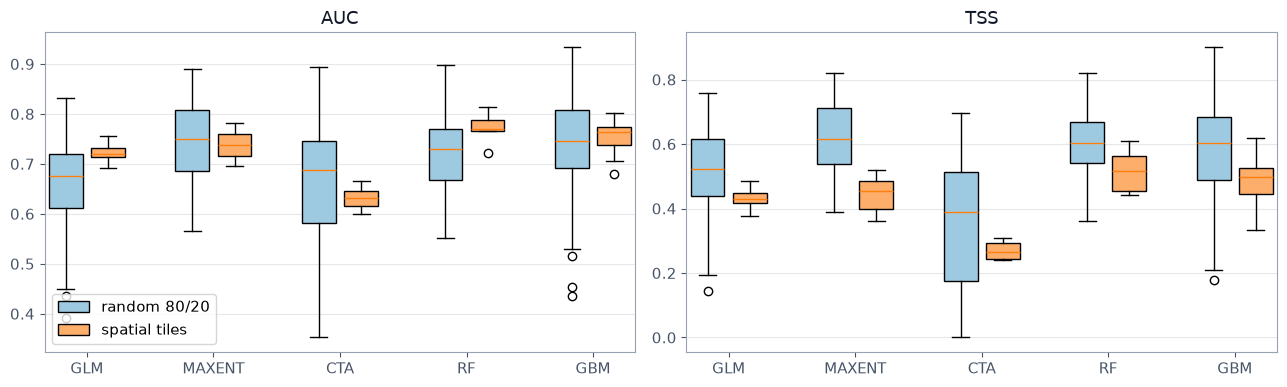

pa_set,0,1,2,3,4,5,6,7
AUC,0.731,0.758,0.700,0.722,0.746,0.702,0.712,0.722
TSS,0.442,0.483,0.378,0.409,0.475,0.398,0.419,0.428


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["AUC", "TSS"]):
    data = [evals[(evals.model == m) & (evals.scheme == sch)][metric] for m in make_models()
            for sch in ["random 80/20", "spatial (0.3° tiles)"]]
    pos = [i * 3 + j for i in range(len(make_models())) for j in (0, 1)]
    bp = ax.boxplot(data, positions=pos, widths=0.8, patch_artist=True)
    for patch, j in zip(bp["boxes"], [0, 1] * len(make_models())):
        patch.set_facecolor(["#9ecae1", "#fdae6b"][j])
    ax.set_xticks([i * 3 + 0.5 for i in range(len(make_models()))], list(make_models()))
    ax.set_title(metric)
    ax.grid(axis="y", alpha=0.3)
axes[0].legend([bp["boxes"][0], bp["boxes"][1]], ["random 80/20", "spatial tiles"], loc="lower left")
plt.tight_layout()
plt.show()

# Stability across the eight background sets (paper: Table S7).
display(evals[evals.scheme.str.startswith("spatial")].groupby("pa_set")[["AUC", "TSS"]].mean().T.round(3))

**Reading the evaluation.** Two things stand out.

- **Random splits are mostly noise here.** A 20 percent test set holds only about four presences, so a single split can give an AUC anywhere from 0.4 to 0.9. Mean AUC under random splits is about the same as, or lower than, under spatial tiles; only TSS comes out higher, because with four test presences one lucky threshold separates them easily. Spatial cross-validation pools out-of-fold predictions for all 22 presences, which gives a far more stable estimate.
- **The honest skill is moderate.** Spatial AUCs of 0.72 to 0.78 for GLM, MaxEnt-style, RF and GBM, and 0.64 for the single tree, describe a model that ranks occupied blocks above the background clearly but far from perfectly.

The paper's very high scores (mean ROC up to 0.999 for RF) come from random splits on 177 precise points. They measure something different and are not comparable with the scores here.

The ensemble below uses the **spatial** scores: an algorithm enters only if its mean spatial AUC is at least 0.70, and members are weighted by that AUC (the paper's `EMwmean` rule, with a lower bar suited to an honest test on 22 blocks).

In [14]:
spatial_auc = evals[evals.scheme.str.startswith("spatial")].groupby("model")["AUC"].mean()
members_B = spatial_auc[spatial_auc >= 0.70]
if members_B.empty:  # never leave the ensemble empty
    members_B = spatial_auc.nlargest(2)
print("Ensemble members and AUC weights:")
display(members_B.to_frame("weight (spatial AUC)"))

# Fit every member on all presences with each background set, predict every 270 m cell, average.
t0 = time.time()
pred = {}
fitted = {name: [] for name in members_B.index}
for name in members_B.index:
    maps = []
    for bg in pa_sets:
        X, y, _ = assemble(bg)
        model = make_models()[name].fit(X, y)
        fitted[name].append(model)
        p = np.full(Xgrid.shape[0], np.nan)
        p[valid_idx] = model.predict_proba(Xgrid[valid_idx])[:, 1]
        maps.append(p)
    pred[name] = np.nanmean(maps, axis=0)
w = members_B / members_B.sum()
hsi_B270 = sum(w[name] * pred[name] for name in members_B.index).reshape(valid270.shape)
hsi_B270 = np.where(valid270, hsi_B270, np.nan)
print(f"Ensemble prediction in {time.time() - t0:.0f} s")


def ensemble_predict(X):
    """AUC-weighted mean over members, averaged over the eight background sets."""
    return sum(w[n] * np.mean([m.predict_proba(X)[:, 1] for m in fitted[n]], axis=0) for n in members_B.index)

Ensemble members and AUC weights:


,weight (spatial AUC)
model,
GBM,0.751
GLM,0.722
MAXENT,0.739
RF,0.775


Ensemble prediction in 18 s


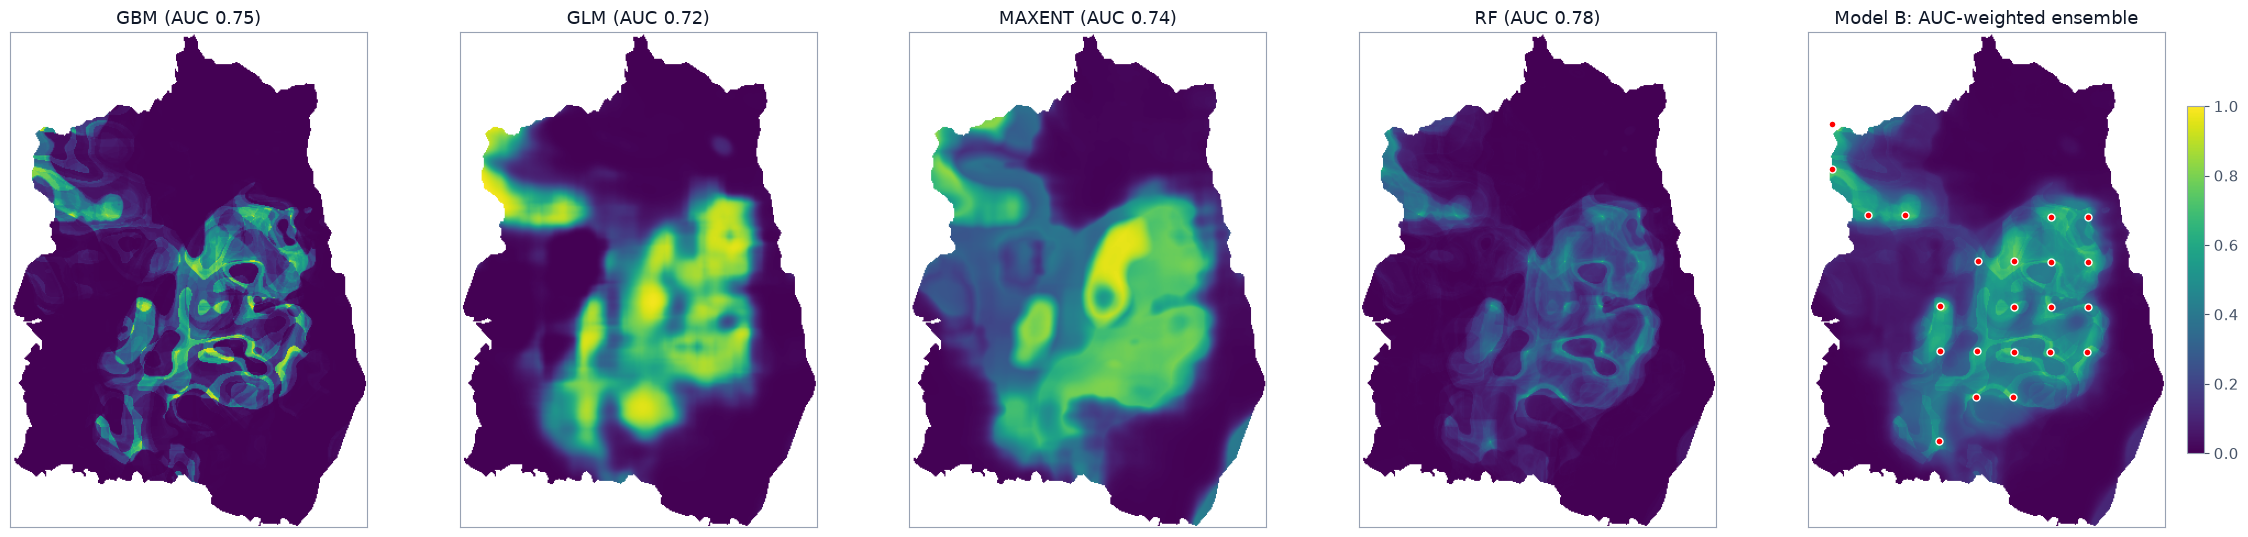

In [15]:
ext270 = (EXTENT[0], EXTENT[0] + valid270.shape[1] * CELL_B, EXTENT[3] - valid270.shape[0] * CELL_B, EXTENT[3])
fig, axes = plt.subplots(1, len(members_B) + 1, figsize=(4.6 * (len(members_B) + 1), 5.5))
for ax, name in zip(axes, list(members_B.index)):
    ax.imshow(np.where(valid270, pred[name].reshape(valid270.shape), np.nan), cmap="viridis", extent=ext270, vmin=0, vmax=1)
    ax.set_title(f"{name} (AUC {members_B[name]:.2f})")
im = axes[-1].imshow(hsi_B270, cmap="viridis", extent=ext270, vmin=0, vmax=1)
axes[-1].scatter(sites.x, sites.y, c="red", s=25, edgecolor="white", zorder=5)
axes[-1].set_title("Model B: AUC-weighted ensemble")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.colorbar(im, ax=axes[-1], fraction=0.04)
plt.tight_layout()
plt.show()

### Variable importance and response curves

Importance is measured by permutation on the ensemble: shuffle one predictor, and record how much the AUC on the fitted data drops. Contributions are the drops rescaled to sum to 100, the same presentation as the paper.

,contribution (%)
dist_settlement,44.670
dist_road,18.194
slope_mean,9.965
needleleaf_share,7.927
dist_river,6.089
warm_temperature,5.046
slope_share_gt22,4.316
precipitation,3.795


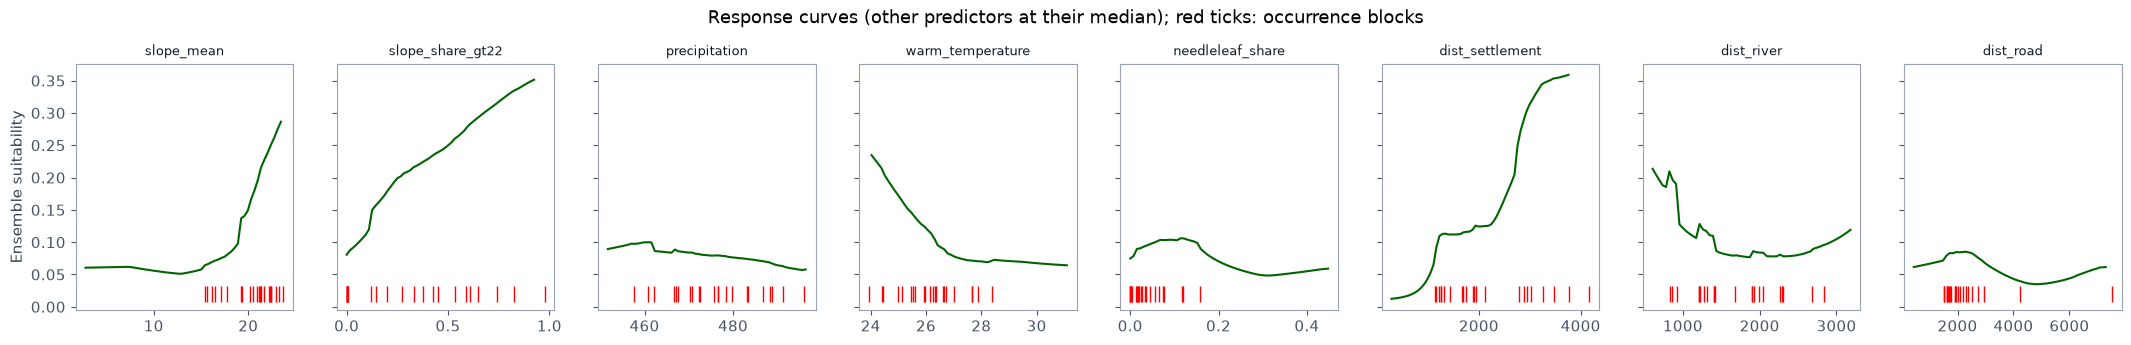

In [16]:
X_all, y_all, _ = assemble(np.concatenate(pa_sets))
base_auc = roc_auc_score(y_all, ensemble_predict(X_all))
drops = {}
for j, name in enumerate(FEATURES):
    d = []
    for rep in range(5):
        Xp = X_all.copy()
        Xp[:, j] = RNG.permutation(Xp[:, j])
        d.append(base_auc - roc_auc_score(y_all, ensemble_predict(Xp)))
    drops[name] = max(np.mean(d), 0.0)
imp = pd.Series(drops)
imp = (100 * imp / imp.sum()).sort_values(ascending=False).rename("contribution (%)")
display(imp.to_frame())

fig, axes = plt.subplots(1, len(FEATURES), figsize=(3.3 * len(FEATURES), 3.2), sharey=True)
med = np.nanmedian(X_all, axis=0)
for j, (ax, name) in enumerate(zip(axes, FEATURES)):
    grid_j = np.linspace(np.nanpercentile(Xgrid[valid_idx, j], 1), np.nanpercentile(Xgrid[valid_idx, j], 99), 60)
    Xr = np.tile(med, (60, 1))
    Xr[:, j] = grid_j
    ax.plot(grid_j, ensemble_predict(Xr), color="darkgreen")
    ax.plot(X_pres[:, j], np.zeros(len(X_pres)) + 0.02, "|", color="red", markersize=12)
    ax.set_title(name, fontsize=9)
axes[0].set_ylabel("Ensemble suitability")
plt.suptitle("Response curves (other predictors at their median); red ticks: occurrence blocks", y=1.05)
plt.show()

**Reading the importance and response curves.** The response shapes agree in direction with the paper: suitability rises with mean slope and with the share of steep land, falls as warm-month temperature rises, rises with distance from settlements and falls with distance from rivers. Precipitation has an almost flat response.

The **ranking** differs. Distance to settlements carries about 45 percent of the importance and distance to roads about 18 percent, while slope and climate together carry less than a third. The paper found the reverse (slope 56 %, precipitation 19 %, temperature 13 %, every disturbance variable < 5 %). Three reasons are likely, and they are worth stating because each is a general lesson:

1. **Survey design.** The transects were laid out in and around the three reserves, which sit in the remote, road-poor centre of the area. At 10 km resolution "far from villages and roads" is what most distinguishes the surveyed blocks from the rest of the landscape, whether or not the deer select for it.
2. **Unit of analysis.** Inside a 10 km block, almost every block contains some steep land, so block-mean slope varies less than cell slope. The paper's strong slope effect is partly a fine-scale effect that block summaries cannot see.
3. **Correlated predictors share credit.** Remote blocks are also the steep, forested, cooler ones; permutation importance assigns the shared signal to whichever variable the models used first.

This is why Model B is used only as **landscape context** and is combined with Model A, whose weights come from the paper's fine-scale analysis.

## Combining the two models

The two maps answer different questions. Model A asks whether a 90 m cell offers what the species needs. Model B asks whether the surrounding 10 km of landscape looks like the landscapes where the species was found. The combined suitability is their **geometric mean**,

$$
h = \sqrt{A \cdot B},
$$

which stays low when either model is low: one model cannot compensate for the other.

Correlation between Model A and Model B across 90 m cells: r = 0.68


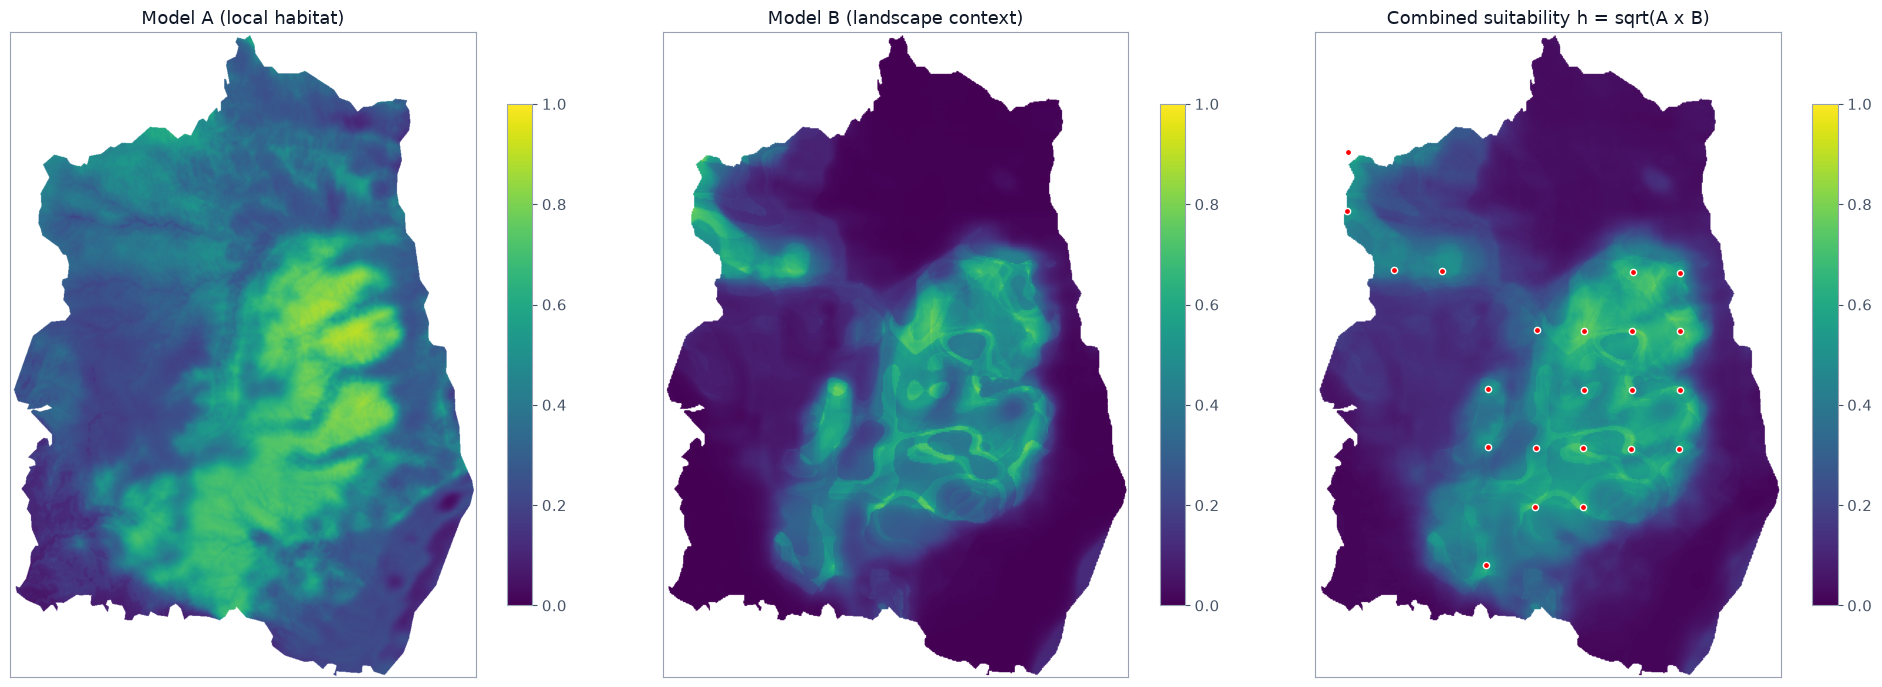

In [17]:
B90 = np.repeat(np.repeat(hsi_B270, AGG, axis=0), AGG, axis=1)  # back to 90 m
B90 = np.pad(B90, ((0, valid.shape[0] - B90.shape[0]), (0, valid.shape[1] - B90.shape[1])), constant_values=np.nan)
B90 = np.where(valid, B90, np.nan)
hsi = np.sqrt(np.clip(hsi_A, 0, 1) * np.clip(B90, 0, 1))

both = valid & np.isfinite(B90)
r_AB = np.corrcoef(hsi_A[both], B90[both])[0, 1]
print(f"Correlation between Model A and Model B across 90 m cells: r = {r_AB:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for ax, arr, title in zip(axes, [hsi_A, B90, hsi], ["Model A (local habitat)", "Model B (landscape context)",
                                                     "Combined suitability h = sqrt(A x B)"]):
    im = ax.imshow(arr, cmap="viridis", extent=EXTENT, vmin=0, vmax=1)
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(im, ax=ax, fraction=0.04)
axes[2].scatter(sites.x, sites.y, c="red", s=20, edgecolor="white", zorder=5)
plt.tight_layout()
plt.show()

## Primary habitat patches

The paper defines primary habitat in two steps: a presence-based threshold on the suitability map, then a minimum patch size. The threshold step needs care here.

**Why a presence threshold cannot be set at 90 m.** The paper's threshold (the lowest presence threshold at 90 percent, LPT90) is the suitability value exceeded at 90 percent of the occurrence points. With precise points that is well defined. Here each record is a 10 km block, so the 90 m value "at" a record does not exist.

**What is done instead.**

1. **Landscape mask from Model B.** LPT90 is applied to Model B, which works at block scale. The values used are **out-of-fold** predictions from the spatial cross-validation: what the ensemble predicts for each occurrence block when that block was left out. In-sample predictions would set the bar far too high, because the tree ensembles reproduce their 22 training blocks almost perfectly.
2. **Equal-area selection on the combined map.** Within that mask, the cells with the highest combined suitability $h$ are kept until they cover **11.8 percent** of the study area, the share the paper classed as primary habitat (863 of 7,293 km²). This is an explicit decision, not an estimate: it makes the configuration of habitat directly comparable with the published map, and the sensitivity table below shows what other shares would give.
3. **Patch size.** Connected cells (8-neighbour) forming at least **76 ha**, the average home range used by the paper (Liu et al. 2020).

In [18]:
# Out-of-fold ensemble value at each presence: what the ensemble predicts for a block it did not see.
oof_ens = sum(w[n] * np.nanmean([oof_presence[(s, n)] for s in range(len(pa_sets))], axis=0) for n in members_B.index)
insample = hsi_B270.ravel()[pres_cells]
print(f"Model B at the presences: in-sample median {np.median(insample):.2f}, out-of-fold median {np.nanmedian(oof_ens):.2f}")
lpt90 = float(np.nanpercentile(oof_ens, 10))
print(f"LPT90 on Model B (out-of-fold): {lpt90:.3f}; cells above it: {np.nanmean(B90[valid] >= lpt90):.0%} of the area")

TOP_SHARE = 863.0 / 7292.8  # share of the study area classed as primary habitat by Zheng et al. (2026)
MIN_PATCH_HA = 76.0


def primary_patches(top_share=TOP_SHARE, b_thr=lpt90, min_ha=MIN_PATCH_HA):
    """Top `top_share` of h inside the Model B mask, then patches of at least `min_ha`."""
    mask = valid & (B90 >= b_thr)
    h_thr = np.nanquantile(hsi[valid], 1 - top_share)  # equal-area cut on the whole study area
    suitable = mask & (hsi >= h_thr)
    lab, n = ndimage.label(suitable, structure=np.ones((3, 3)))
    sizes = np.bincount(lab.ravel())[1:] * CELL_HA
    keep_ids = np.flatnonzero(sizes >= min_ha) + 1
    order = keep_ids[np.argsort(-sizes[keep_ids - 1])]
    relabel = np.zeros(lab.max() + 1, dtype=int)
    relabel[order] = np.arange(1, len(order) + 1)
    lab = relabel[lab]
    tab = pd.DataFrame({"patch": np.arange(1, len(order) + 1), "area_km2": np.sort(sizes[keep_ids - 1])[::-1] / 100})
    return lab, tab, h_thr


patches, patch_tab, h_cut = primary_patches()
print(f"Combined-suitability cut for the top {TOP_SHARE:.1%}: h >= {h_cut:.3f}")
print(f"Primary habitat: {len(patch_tab)} patches, {patch_tab.area_km2.sum():,.1f} km2 "
      f"({patch_tab.area_km2.sum() / (valid.sum() * CELL_HA / 100):.1%} of the study area)")
patch_tab["share_%"] = 100 * patch_tab.area_km2 / patch_tab.area_km2.sum()
patch_tab["mean_h"] = [np.nanmean(hsi[patches == p]) for p in patch_tab.patch]
patch_tab["mean_slope_deg"] = [np.nanmean(slope[patches == p]) for p in patch_tab.patch]
display(patch_tab.head(10))

Model B at the presences: in-sample median 0.78, out-of-fold median 0.22
LPT90 on Model B (out-of-fold): 0.135; cells above it: 40% of the area
Combined-suitability cut for the top 11.8%: h >= 0.534
Primary habitat: 6 patches, 857.1 km2 (11.8% of the study area)


,patch,area_km2,share_%,mean_h,mean_slope_deg
0,1,828.387,96.650,0.609,22.440
1,2,15.422,1.799,0.557,21.037
2,3,7.930,0.925,0.572,22.090
3,4,2.697,0.315,0.544,21.899
4,5,1.507,0.176,0.564,17.451
5,6,1.158,0.135,0.544,16.765


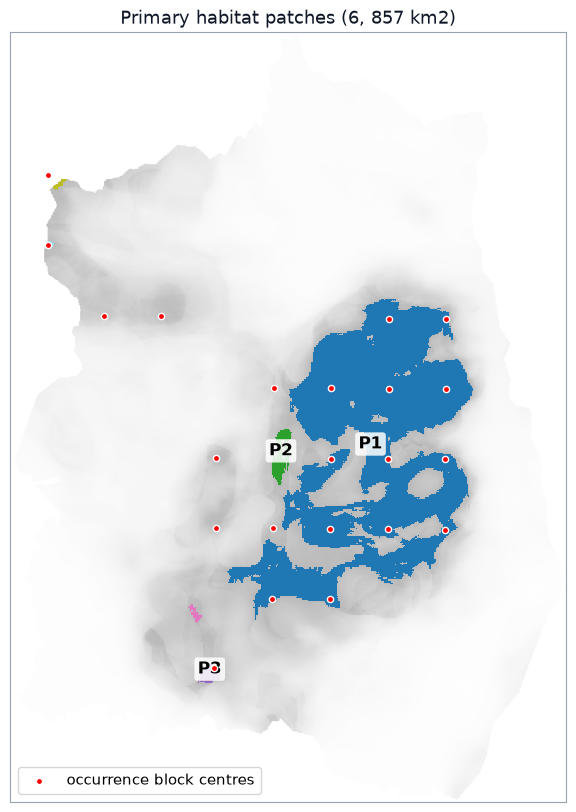

In [19]:
fig, ax = plt.subplots(figsize=(9, 10))
ax.imshow(np.where(valid, hsi, np.nan), cmap="Greys", extent=EXTENT, vmin=0, vmax=1, alpha=0.6)
pm = np.where(patches > 0, patches, np.nan)
ax.imshow(pm, cmap="tab20", extent=EXTENT, interpolation="nearest")
for p in patch_tab.patch[:3]:
    r, c = np.argwhere(patches == p).mean(axis=0)
    x, y = dp.rowcol_to_xy(int(r), int(c), GT)
    ax.annotate(f"P{p}", (x, y), fontsize=12, fontweight="bold", ha="center",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.85, lw=0))
ax.scatter(sites.x, sites.y, c="red", s=20, edgecolor="white", zorder=5, label="occurrence block centres")
ax.legend(loc="lower left")
ax.set_title(f"Primary habitat patches ({len(patch_tab)}, {patch_tab.area_km2.sum():,.0f} km2)")
ax.set_xticks([]); ax.set_yticks([])
plt.show()

### How much do the choices matter?

In [20]:
sens = []
for share in [0.08, TOP_SHARE, 0.16]:
    for label, b_thr in [("no mask", -np.inf), ("LPT80", float(np.nanpercentile(oof_ens, 20))), ("LPT90", lpt90)]:
        lab_s, tab_s, _ = primary_patches(share, b_thr)
        sens.append({"top share": f"{share:.1%}", "Model B mask": label, "patches": len(tab_s),
                     "area_km2": round(tab_s.area_km2.sum()),
                     "largest_km2": round(tab_s.area_km2.max()) if len(tab_s) else 0})
sens = pd.DataFrame(sens)
display(sens.pivot(index="top share", columns="Model B mask", values="patches").rename_axis(columns="patches"))
display(sens.pivot(index="top share", columns="Model B mask", values="largest_km2").rename_axis(columns="largest patch (km2)"))

patches,LPT80,LPT90,no mask
top share,,,
11.8%,6,6,6
16.0%,10,10,10
8.0%,10,10,10


largest patch (km2),LPT80,LPT90,no mask
top share,,,
11.8%,828,828,828
16.0%,1100,1100,1100
8.0%,492,492,492


**Reading the sensitivity tables.** The Model B mask removes nothing at these shares: every cell in the top 16 percent of combined suitability already lies inside the area where Model B exceeds LPT80, so Model B acts through the combined score, not through the mask. The selected share, in contrast, changes the configuration. At the paper's 11.8 percent, one patch holds about 97 percent of primary habitat; at 8 percent it breaks into more, smaller patches; at 16 percent it grows further. The paper's two largest patches (421 and 362 km²) are separated by its corridor L1. Here they are most likely merged into one patch, because block-scale context and the smooth slope layer do not resolve the narrow gap between them. Patch counts and the corridor network below should be read with that in mind.

## Weight uncertainty in Model A

Only three of Model A's seven weights come from the paper. `monte_carlo_weights` draws 500 weight vectors from a Dirichlet distribution centred on the baseline (concentration κ = 50) and reports, for every cell, the spread of the resulting HSI and the probability that the cell stays in the top 10 percent. It runs on the 270 m grid to keep memory modest.

Monte Carlo weights: 3 s; median Jaccard of top-10% sets vs baseline 0.81


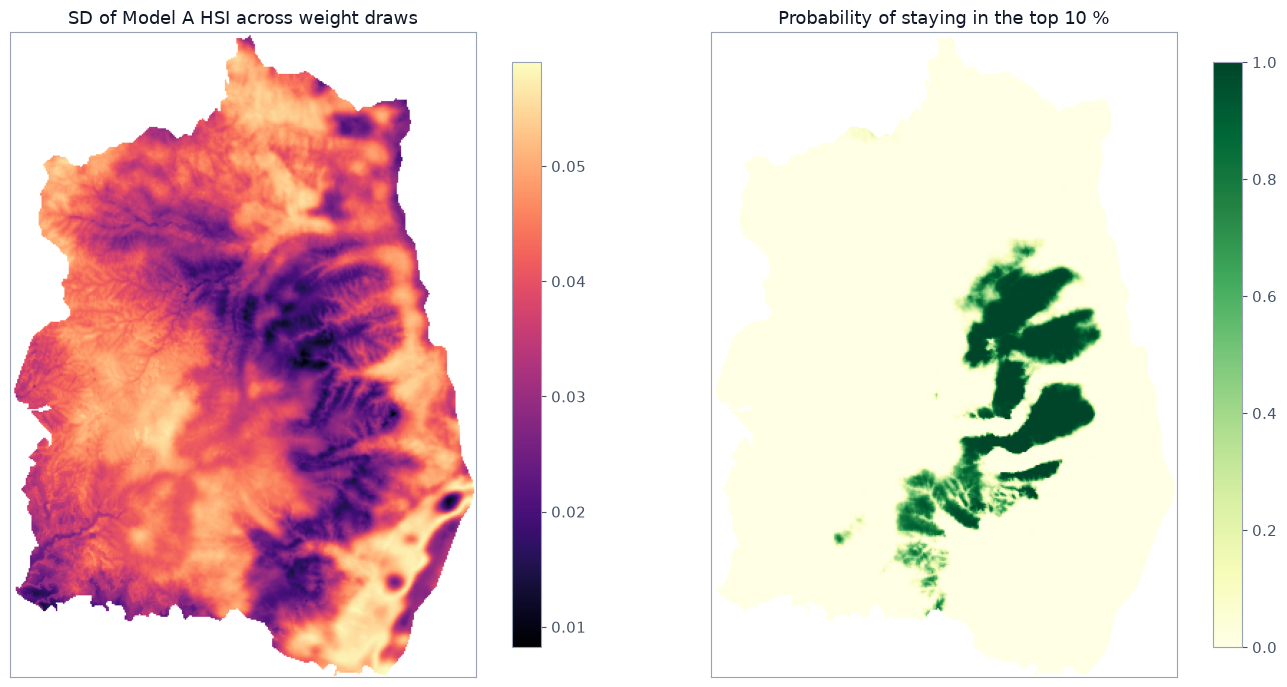

In [21]:
names_mc = list(WEIGHTS_A)
M = np.stack([coarsen(np.where(valid, members[k], np.nan))[valid270] for k in names_mc])
M = np.nan_to_num(M)
t0 = time.time()
mc = monte_carlo_weights(M, np.array([WEIGHTS_A[k] for k in names_mc]), kappa=50.0, n=500, batch=50, top_q=0.9, seed=7)
print(f"Monte Carlo weights: {time.time() - t0:.0f} s; median Jaccard of top-10% sets vs baseline "
      f"{np.median(mc['jaccard']):.2f}")


def to_grid270(vec):
    g = np.full(valid270.shape, np.nan)
    g[valid270] = vec
    return g


fig, axes = plt.subplots(1, 2, figsize=(15, 7))
im0 = axes[0].imshow(to_grid270(mc["sd"]), cmap="magma", extent=ext270)
axes[0].set_title("SD of Model A HSI across weight draws")
plt.colorbar(im0, ax=axes[0], fraction=0.04)
im1 = axes[1].imshow(to_grid270(mc["p_top"]), cmap="YlGn", extent=ext270, vmin=0, vmax=1)
axes[1].set_title("Probability of staying in the top 10 %")
plt.colorbar(im1, ax=axes[1], fraction=0.04)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

The spread is small compared with the range of the HSI, and the core steep blocks stay in the top 10 percent in nearly every draw. Cells near the edge of the top set are the ones whose status depends on the weight split; they are also where the patch boundaries above are least certain.

## Resistance surface

Connectivity starts from a **resistance surface**: the cost for an animal to cross a cell. The paper converts suitability $h$ into resistance with a negative exponential (Keeley et al. 2016):

$$
R = 100 - 99 \cdot \frac{1 - e^{-c h}}{1 - e^{-c}}
$$

$R$ runs from 1 (best habitat) to 100 (worst). The parameter $c$ sets the curvature. A habitat specialist may tolerate mediocre habitat while dispersing, so resistance should stay low over intermediate suitability and rise sharply only in poor habitat; the paper uses $c = 8$ as baseline and tests 4 to 16.

Connectivity is computed on the 270 m grid.

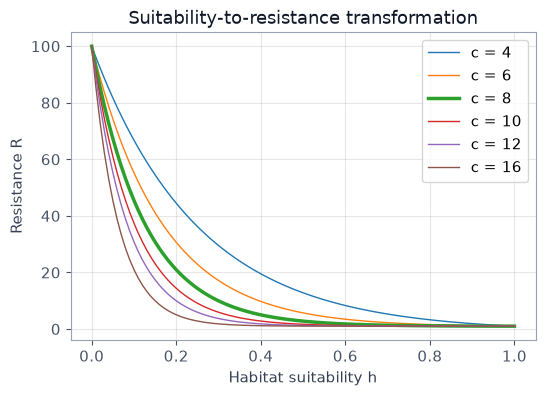

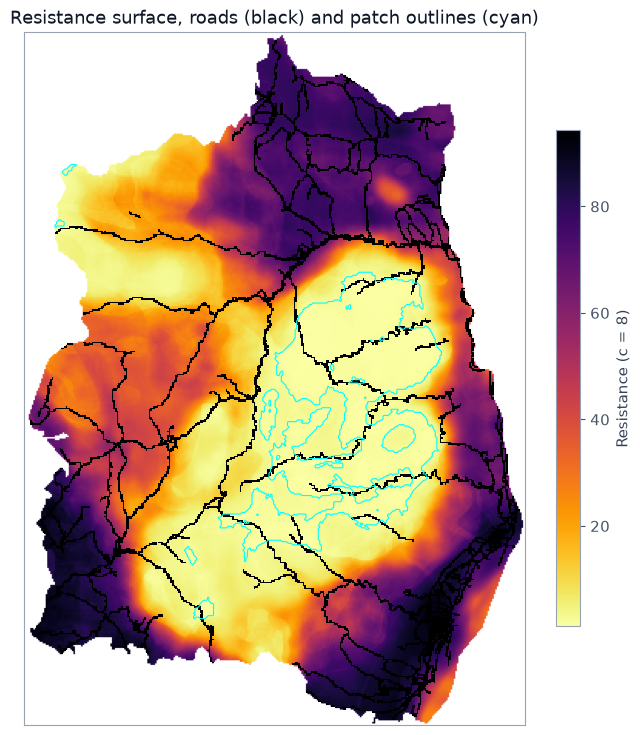

In [22]:
def resistance(h, c):
    return 100.0 - 99.0 * (1.0 - np.exp(-c * h)) / (1.0 - np.exp(-c))


hh = np.linspace(0, 1, 101)
fig, ax = plt.subplots(figsize=(6, 4))
for c in [4, 6, 8, 10, 12, 16]:
    ax.plot(hh, resistance(hh, c), label=f"c = {c}", lw=2.5 if c == 8 else 1)
ax.set_xlabel("Habitat suitability h")
ax.set_ylabel("Resistance R")
ax.legend()
ax.grid(alpha=0.3)
ax.set_title("Suitability-to-resistance transformation")
plt.show()

h270 = np.where(valid270, coarsen(np.where(valid, hsi, np.nan)), np.nan)
patch270 = coarsen(np.where(valid, patches.astype(float), np.nan), how="max")
patch270 = np.where(valid270, np.nan_to_num(patch270), 0).astype(int)
roads270 = coarsen(roads.astype(float), how="max") > 0
roads270 &= valid270
R8 = np.where(valid270, resistance(np.nan_to_num(h270), 8.0), np.nan)

fig, ax = plt.subplots(figsize=(8, 9))
im = ax.imshow(R8, cmap="inferno_r", extent=ext270)
ax.imshow(np.where(roads270, 1.0, np.nan), cmap="Greys", vmin=0, vmax=1, extent=ext270, interpolation="nearest")
ax.contour(patch270 > 0, levels=[0.5], colors="cyan", linewidths=0.8, extent=ext270, origin="upper")
plt.colorbar(im, ax=ax, fraction=0.04, label="Resistance (c = 8)")
ax.set_title("Resistance surface, roads (black) and patch outlines (cyan)")
ax.set_xticks([]); ax.set_yticks([])
plt.show()

## Least-cost corridors

The **cost-weighted distance** (CWD) from a patch to any cell is the minimum sum of resistance times distance along a path. Following Linkage Mapper (McRae and Kavanagh 2011), patches are linked when their cost-distance zones touch, that is, when no third patch lies between them in cost space. For each link the notebook reports:

- the **least-cost path** (LCP) and its length;
- the CWD between the patches and the Euclidean distance between their edges;
- the ratio **CWD : EucD**. A ratio near 1 would mean an easy, straight route through good habitat; larger values mean detours or costly ground.

Cost distance is computed with Dijkstra's algorithm (`scipy.sparse.csgraph.dijkstra`) on the 8-neighbour cell graph. The cost of moving between neighbouring cells is the mean of their resistances times the step length.

In [23]:
NR, NC = valid270.shape
node_of = -np.ones(NR * NC, dtype=np.int64)
node_of[valid_idx] = np.arange(valid_idx.size)
STEPS = [(0, 1, 1.0), (1, 0, 1.0), (1, 1, np.sqrt(2)), (1, -1, np.sqrt(2))]  # each undirected edge once


def edges_for(R):
    """Undirected 8-neighbour edges (i, j, step_length_m, mean_resistance)."""
    I, J, L, RM = [], [], [], []
    rr, cc = np.divmod(valid_idx, NC)
    for dr, dc, s in STEPS:
        r2, c2 = rr + dr, cc + dc
        ok = (r2 >= 0) & (r2 < NR) & (c2 >= 0) & (c2 < NC)
        nb = np.full(rr.shape, -1)
        nb[ok] = node_of[r2[ok] * NC + c2[ok]]
        ok &= nb >= 0
        a, b = np.arange(valid_idx.size)[ok], nb[ok]
        I.append(a); J.append(b); L.append(np.full(a.size, s * CELL_B))
        Rf = R.ravel()[valid_idx]
        RM.append(0.5 * (Rf[a] + Rf[b]))
    return np.concatenate(I), np.concatenate(J), np.concatenate(L), np.concatenate(RM)


def cost_graph(R):
    I, J, L, RM = edges_for(R)
    n = valid_idx.size
    return sparse.coo_matrix((L * RM, (I, J)), shape=(n, n)).tocsr()


patch_nodes = {p: node_of[np.flatnonzero(patch270.ravel() == p)] for p in np.unique(patch270) if p > 0}
patch_nodes = {p: v[v >= 0] for p, v in patch_nodes.items() if (v >= 0).any()}
print(f"Patches on the 270 m grid: {len(patch_nodes)}")


def corridors(R):
    """Cost distances from each patch, adjacent links, least-cost paths and their statistics."""
    G = cost_graph(R)
    cd, pred = {}, {}
    for p, nodes in patch_nodes.items():
        d, pr, _ = csgraph.dijkstra(G, directed=False, indices=nodes, min_only=True, return_predecessors=True)
        cd[p], pred[p] = d, pr
    # Allocation: nearest patch in cost space for every node; links where allocation zones touch.
    ids = np.array(list(cd))
    D = np.vstack([cd[p] for p in ids])
    alloc = ids[np.argmin(D, axis=0)]
    I, J, _, _ = edges_for(R)
    pairs = {tuple(sorted(x)) for x in zip(alloc[I], alloc[J]) if x[0] != x[1]}
    xy = np.column_stack(dp.rowcol_to_xy(*np.divmod(valid_idx, NC), (ext270[0], CELL_B, 0, ext270[3], 0, -CELL_B)))
    links = []
    for a, b in sorted(pairs):
        tot = cd[a] + cd[b]
        k = int(np.argmin(tot))
        cwd = float(tot[k])
        # Trace the least-cost path from the best meeting node back into each patch.
        def trace(p):  # nodes from the meeting node k back to patch p
            n, seg = k, []
            while n >= 0:
                seg.append(n)
                n = pred[p][n]
            return seg

        path = np.array(trace(a)[::-1] + trace(b)[1:])  # patch a -> k -> patch b
        # Drop links whose least-cost path runs through a third patch (Linkage Mapper rule).
        others = patch270.ravel()[valid_idx[path]]
        if np.any((others > 0) & (others != a) & (others != b)):
            continue
        steps = np.hypot(*np.diff(xy[path], axis=0).T).sum() if len(path) > 1 else 0.0
        # Edge-to-edge Euclidean distance between the two patches.
        from scipy.spatial import cKDTree

        tree = cKDTree(xy[patch_nodes[b]])
        euc = float(tree.query(xy[patch_nodes[a]])[0].min())
        links.append({"from": a, "to": b, "cwd": cwd, "lcp_length_m": steps, "euclid_m": max(euc, CELL_B),
                      "path": path})
    links = pd.DataFrame(links)
    links["cwd_to_euclid"] = links.cwd / links.euclid_m
    return links, cd


t0 = time.time()
links8, cd8 = corridors(R8)
print(f"Corridors: {len(links8)} links in {time.time() - t0:.0f} s")
display(links8.drop(columns="path").sort_values(["from", "to"]).head(12).round(1))
print(f"LCP length: {links8.lcp_length_m.min():.0f} to {links8.lcp_length_m.max():,.0f} m "
      f"(mean {links8.lcp_length_m.mean():,.0f} m)")

Patches on the 270 m grid: 6
Corridors: 7 links in 0 s


,from,to,cwd,lcp_length_m,euclid_m,cwd_to_euclid
0,1,2,3475.7,1415.5,1350.0,2.6
1,1,3,43334.2,10969.4,9164.1,4.7
2,1,4,21901.6,6761.2,6536.0,3.4
3,1,5,315959.9,54978.0,47253.1,6.7
4,1,6,290591.7,46542.5,43480.1,6.7
5,3,4,18432.5,7058.4,6524.8,2.8
6,5,6,24158.8,8547.4,8140.4,3.0


LCP length: 1416 to 54,978 m (mean 19,467 m)


With one dominant patch, most links run from that patch to small outlying patches. Two links to the far north-western patches are long (about 47 and 55 km of path). Linkage Mapper would normally drop such links with a maximum-distance setting; they are kept here to show that the north-western occurrence blocks are effectively isolated from the main habitat. The CWD : EucD ratios of the shorter links rank their quality: values near 2 to 3 mean the route follows reasonably good habitat, larger values mean costly detours.

In [24]:
big3 = [1, 2, 3]
key_links = links8[links8["from"].isin(big3) & links8["to"].isin(big3)].copy()
if key_links.empty:
    print("The three largest patches are not directly linked; the paths below are the cheapest links that touch them.")
    key_links = links8[links8["from"].isin(big3) | links8["to"].isin(big3)].nsmallest(3, "cwd_to_euclid")
display(key_links.drop(columns="path").round(2))

,from,to,cwd,lcp_length_m,euclid_m,cwd_to_euclid
0,1,2,3475.75,1415.51,1350.0,2.57
1,1,3,43334.24,10969.40,9164.1,4.73


## Pinch points with circuit theory

A least-cost path is one line. **Circuit theory** (McRae et al. 2008) treats the landscape as an electrical network in which each cell conducts in proportion to $1/R$. Current injected in one patch and drained in another spreads over all routes in proportion to their ease, so it shows how *many* alternatives a corridor has. Where current is forced through a narrow strip, current density peaks: a **pinch point**, the place where losing a little habitat breaks the link.

For each link the notebook

1. restricts the network to the corridor, the cells where $CWD_a + CWD_b \le CWD_{ab} + 10{,}000$ (the paper's cutoff);
2. sets the voltage to 1 in one patch and 0 in the other, and solves Kirchhoff's equations $L\,v = 0$ for the remaining cells with a sparse solver;
3. scales the solution to 1 A and records the current through every cell.

Summing over links gives cumulative current density.

Circuit solves for 7 links in 0 s


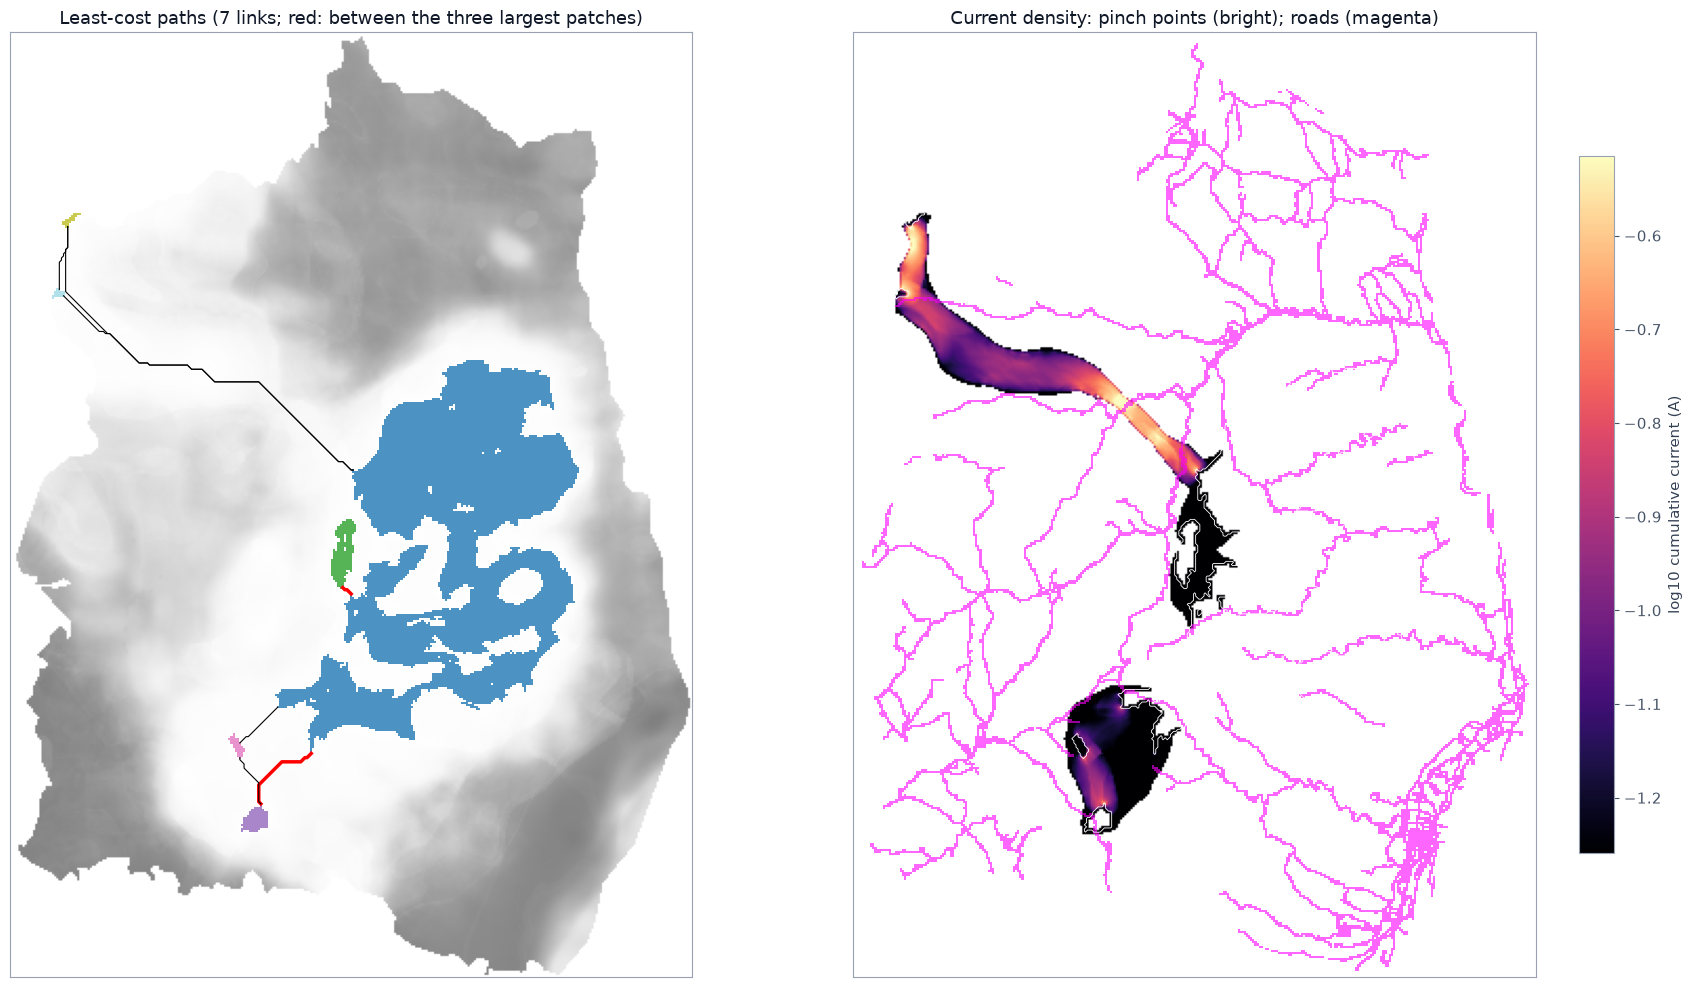

In [25]:
CWD_CUTOFF = 10_000.0


def current_density(R, links, cd):
    """Pairwise circuit current, summed over links, on the 270 m node set."""
    I, J, L, RM = edges_for(R)
    g = (CELL_B / L) / RM  # conductance: 1 / (mean resistance x relative step length)
    n = valid_idx.size
    total = np.zeros(n)
    for _, lk in links.iterrows():
        a, b = int(lk["from"]), int(lk["to"])
        inc = (cd[a] + cd[b]) <= lk.cwd + CWD_CUTOFF
        inc[patch_nodes[a]] = inc[patch_nodes[b]] = True
        sub = np.flatnonzero(inc)
        loc = -np.ones(n, dtype=np.int64)
        loc[sub] = np.arange(sub.size)
        e = inc[I] & inc[J]
        ii, jj, gg = loc[I[e]], loc[J[e]], g[e]
        m = sub.size
        Lap = sparse.coo_matrix((np.r_[-gg, -gg], (np.r_[ii, jj], np.r_[jj, ii])), shape=(m, m)).tocsr()
        Lap = Lap + sparse.diags(-np.asarray(Lap.sum(axis=1)).ravel())
        fixed = np.zeros(m, dtype=bool)
        v = np.zeros(m)
        src, snk = loc[patch_nodes[a]], loc[patch_nodes[b]]
        fixed[src] = fixed[snk] = True
        v[src] = 1.0
        free = ~fixed
        if free.sum() == 0:
            continue
        A = Lap[free][:, free].tocsc()
        rhs = -Lap[free][:, fixed] @ v[fixed]
        v[free] = spsolve(A, rhs)
        flow = gg * np.abs(v[ii] - v[jj])  # current on each edge
        node_cur = np.zeros(m)
        np.add.at(node_cur, ii, flow)
        np.add.at(node_cur, jj, flow)
        injected = (Lap[src] @ v).sum()  # total current leaving the source patch
        if injected > 0:
            total[sub] += 0.5 * node_cur / injected
    return total


t0 = time.time()
cur8 = current_density(R8, links8, cd8)
print(f"Circuit solves for {len(links8)} links in {time.time() - t0:.0f} s")
cur_grid = np.full(NR * NC, np.nan)
cur_grid[valid_idx] = cur8
cur_grid = cur_grid.reshape(NR, NC)

fig, axes = plt.subplots(1, 2, figsize=(18, 10))
axes[0].imshow(R8, cmap="Greys", extent=ext270, alpha=0.5)
axes[0].imshow(np.where(patch270 > 0, patch270, np.nan), cmap="tab20", extent=ext270, interpolation="nearest", alpha=0.8)
xy_nodes = np.column_stack(dp.rowcol_to_xy(*np.divmod(valid_idx, NC), (ext270[0], CELL_B, 0, ext270[3], 0, -CELL_B)))
for _, lk in links8.iterrows():
    is_key = lk["from"] in big3 and lk["to"] in big3
    axes[0].plot(*xy_nodes[lk.path].T, color="red" if is_key else "black", lw=2.5 if is_key else 0.8)
axes[0].set_title(f"Least-cost paths ({len(links8)} links; red: between the three largest patches)")
show = np.where(cur_grid > 0, cur_grid, np.nan)
im = axes[1].imshow(np.log10(show), cmap="magma", extent=ext270,
                    vmin=np.nanpercentile(np.log10(show), 40), vmax=np.nanpercentile(np.log10(show), 99.5))
axes[1].imshow(np.where(roads270, 1.0, np.nan), cmap="cool", vmin=0, vmax=1, extent=ext270, interpolation="nearest",
               alpha=0.6)
axes[1].contour(patch270 > 0, levels=[0.5], colors="white", linewidths=0.6, extent=ext270, origin="upper")
plt.colorbar(im, ax=axes[1], fraction=0.04, label="log10 cumulative current (A)")
axes[1].set_title("Current density: pinch points (bright); roads (magenta)")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

### Where pinch points meet roads

Pinch points are defined here as corridor cells outside patches in the top 5 percent of current. The cell below lists the road cells among them, the places where a crossing structure would do most for connectivity.

In [26]:
in_corr = (cur_grid > 0) & (patch270 == 0)
pp_thr = np.nanpercentile(cur_grid[in_corr], 95)
pinch = in_corr & (cur_grid >= pp_thr)
road_pinch = pinch & roads270
print(f"Pinch-point cells: {pinch.sum()}  |  on roads: {road_pinch.sum()} ({road_pinch.sum() / max(pinch.sum(), 1):.0%})")
print(f"Share of all corridor cells that are road cells: {(in_corr & roads270).sum() / in_corr.sum():.0%}")

r_, c_ = np.nonzero(road_pinch)
to_ll = Transformer.from_crs(CRS_UTM, "EPSG:4326", always_xy=True)
xs, ys = ext270[0] + (c_ + 0.5) * CELL_B, ext270[3] - (r_ + 0.5) * CELL_B
lon, lat = to_ll.transform(xs, ys)
crossings = pd.DataFrame({"current_A": cur_grid[r_, c_], "x": xs, "y": ys, "lon": lon, "lat": lat})
crossings = crossings.sort_values("current_A", ascending=False)
display(crossings.head(10).round({"current_A": 3, "lon": 3, "lat": 3}))

Pinch-point cells: 310  |  on roads: 14 (5%)
Share of all corridor cells that are road cells: 2%


,current_A,x,y,lon,lat
4,0.332,412020.41,3.982e+06,110.024,35.974
1,0.313,412290.41,3.982e+06,110.027,35.976
5,0.309,412290.41,3.982e+06,110.027,35.974
8,0.305,412020.41,3.981e+06,110.024,35.972
9,0.301,412290.41,3.981e+06,110.027,35.972
6,0.295,412560.41,3.982e+06,110.030,35.974
2,0.289,412560.41,3.982e+06,110.030,35.976
7,0.282,412830.41,3.982e+06,110.033,35.974
11,0.281,412020.41,3.981e+06,110.024,35.969
10,0.279,411750.41,3.981e+06,110.021,35.969


Road cells make up a larger share of pinch points than of corridor cells overall, by a factor of two to three. Roads therefore run disproportionately through the narrow parts of corridors, the pattern the paper reports for its corridor L1 and the south-western expressway. The table lists the road cells carrying the most current: the candidate sites for crossing structures.

### Sensitivity to the resistance parameter $c$

In [27]:
sens_c = []
top8 = pinch.copy()
for c in [4, 8, 16]:
    Rc = np.where(valid270, resistance(np.nan_to_num(h270), float(c)), np.nan)
    lk, cdc = corridors(Rc)
    cur = np.full(NR * NC, np.nan)
    cur[valid_idx] = current_density(Rc, lk, cdc)
    cur = cur.reshape(NR, NC)
    inc_c = (cur > 0) & (patch270 == 0)
    top_c = inc_c & (cur >= np.nanpercentile(cur[inc_c], 95))
    k3 = lk[lk["from"].isin(big3) & lk["to"].isin(big3)]
    sens_c.append({"c": c, "links": len(lk), "mean LCP length (m)": lk.lcp_length_m.mean(),
                   "mean CWD:EucD (3 largest)": k3.cwd_to_euclid.mean() if len(k3) else np.nan,
                   "Jaccard of pinch points vs c=8": float((top_c & top8).sum() / max((top_c | top8).sum(), 1))})
display(pd.DataFrame(sens_c).round(2))

,c,links,mean LCP length (m),mean CWD:EucD (3 largest),Jaccard of pinch points vs c=8
0,4,7,19155.04,15.36,0.37
1,8,7,19467.49,3.65,1.00
2,16,8,23168.61,1.12,0.32


The network topology hardly changes with $c$: the same links appear (one extra at $c = 16$). Costs fall as $c$ rises, because a larger $c$ makes resistance drop faster with suitability, so intermediate habitat becomes cheap to cross; the CWD : EucD ratios between the largest patches fall accordingly. The pinch-point cells overlap only partly with the baseline (Jaccard about 0.3 to 0.4), so the exact bottleneck cells depend on $c$ more than the paper reports, although they stay within the same corridors. When locating crossing structures, treat a pinch point as a stretch of corridor rather than an exact cell.

## Protected-area gap analysis (optional external data)

The paper found that 66 percent of primary habitat lies inside the three reserves, leaving 34 percent unprotected. Reserve boundaries are not part of the data release. If a polygon file is placed at `Data/03_spatial_analysis/capstone_spatial_analysis/musk_deer/protected_areas.gpkg` (for example, exported from the World Database on Protected Areas), the cell below reports the protected share of each patch.

In [28]:
PA_FILE = OUT / "protected_areas.gpkg"
if not PA_FILE.exists():
    print(f"No protected-area file at {PA_FILE.relative_to(ROOT)}; gap analysis skipped.")
else:
    from geolattice.raster import rasterize

    pa = gpd.read_file(PA_FILE).to_crs(CRS_UTM)
    tmp = OUT / "_pa.gpkg"
    pa.to_file(tmp, driver="GPKG")
    pa_ras = OUT / "protected_90m.tif"
    rasterize(tmp, pa_ras, template=GRID["Slope"], burn_value=1, dtype="uint8", nodata=0, overwrite=True)
    tmp.unlink()
    protected = dp.read_band(pa_ras)[0] == 1
    gap = patch_tab[["patch", "area_km2"]].copy()
    gap["protected_pct"] = [100 * np.mean(protected[patches == p]) for p in gap.patch]
    total = 100 * (protected & (patches > 0)).sum() / (patches > 0).sum()
    print(f"Primary habitat inside protected areas: {total:.1f} %")
    display(gap.head(10))

No protected-area file at Data/03_spatial_analysis/capstone_spatial_analysis/musk_deer/protected_areas.gpkg; gap analysis skipped.


## Outputs

In [29]:
def save90(name, arr):
    return dp.write_band(OUT / name, arr, GRID["Slope"])


save90("hsi_model_a_90m.tif", hsi_A)
save90("hsi_model_b_90m.tif", B90)
save90("hsi_combined_90m.tif", hsi)
dp.write_band(OUT / "primary_patches_90m.tif", np.where(patches > 0, patches, np.nan), GRID["Slope"], nodata=0.0)

geo270 = (ext270[0], CELL_B, 0.0, ext270[3], 0.0, -CELL_B)
for name, arr in [("resistance_c8_270m.tif", R8), ("current_density_c8_270m.tif", cur_grid)]:
    write_raster_data(OUT / name, np.where(np.isfinite(arr), arr, -9999).astype("float32"), crs=CRS_UTM,
                      geotransform=geo270, nodata=-9999.0, overwrite=True)

# Patches and corridors as vectors.
polygonize(OUT / "primary_patches_90m.tif", OUT / "_patches.gpkg", field_name="patch", overwrite=True)
pg = gpd.read_file(OUT / "_patches.gpkg")
pg = pg[pg.patch > 0].dissolve(by="patch").reset_index().merge(patch_tab, on="patch")
(OUT / "_patches.gpkg").unlink()
from shapely.geometry import LineString

lines = gpd.GeoDataFrame(links8.drop(columns="path"),
                         geometry=[LineString(xy_nodes[p]) if len(p) > 1 else LineString([xy_nodes[p[0]], xy_nodes[p[0]]])
                                   for p in links8.path], crs=CRS_UTM)
GPKG = OUT / "musk_deer_habitat_connectivity.gpkg"
pg.to_file(GPKG, layer="primary_patches", driver="GPKG")
lines.to_file(GPKG, layer="least_cost_paths", driver="GPKG")
gpd.GeoDataFrame(crossings, geometry=gpd.points_from_xy(crossings.x, crossings.y), crs=CRS_UTM).to_file(
    GPKG, layer="road_pinch_points", driver="GPKG")
evals.to_csv(OUT / "model_b_evaluation.csv", index=False)
imp.to_csv(OUT / "model_b_variable_importance.csv")

for p in sorted(OUT.glob("*")):
    if p.is_file() and not p.name.endswith("_90m.tif") or p.name.startswith(("hsi", "primary")):
        print(f"  {p.name:45s} {p.stat().st_size / 1024:9.1f} KB")

  current_density_c8_270m.tif                       572.9 KB
  hsi_combined_90m.tif                             5159.3 KB
  hsi_model_a_90m.tif                              5159.3 KB
  hsi_model_b_90m.tif                              5159.3 KB
  model_b_evaluation.csv                             24.7 KB
  model_b_variable_importance.csv                     0.3 KB
  musk_deer_habitat_connectivity.gpkg               208.0 KB
  primary_patches_90m.tif                          5163.1 KB
  resistance_c8_270m.tif                            572.9 KB


## Comparison with the published study, and limitations

| Aspect | Zheng et al. (2026) | This notebook |
|---|---|---|
| Occurrence data | 177 precise points | Same records, coarsened to 23 block centres (22 inside the area) |
| Model | Ensemble of 6 algorithms on 30 m cells | Model A (published requirements, 90 m) x Model B (5-algorithm ensemble on 0.1° block summaries) |
| Validation | Random 80/20 splits | Random and spatial cross-validation |
| Dominant drivers in the published model | Slope 56 %, precipitation 19 %, temperature 13 % | Used as Model A weights |
| Dominant drivers in the data-driven model | Slope, precipitation, temperature | Distance to settlements and roads (Model B, block scale); see Section 6.4 |
| Primary habitat | 19 patches, 863 km²; largest 421, 362, 21 km² | Area set to the paper's share (857 km²); 6 patches, one of about 830 km² |
| Corridors | 25, Linkage Mapper | 7 cost-allocation links with least-cost paths |
| Pinch points | Circuitscape, CWD cutoff 10,000 | Pairwise circuit solves, same cutoff |

**Limitations.**

- **Coordinate generalisation.** The public coordinates are deliberately imprecise. Model B can only learn what distinguishes 10 km landscapes, and its maps are smooth for that reason. Precise points would allow a cell-level model and would almost certainly sharpen and shift the patches.
- **Model A is only as good as its translation of the paper.** Membership shapes were read from published response curves, and four of the seven weights were assigned here.
- **Presence-background design.** Background points are not absences; the outputs are relative suitability, not probability of occurrence. Survey effort was concentrated in and around the reserves, which can bias both the occurrence blocks and the inferred preferences.
- **Sampling bias.** Model B's emphasis on distance from settlements most likely reflects where surveys were done. Target-group background sampling (background drawn from surveyed areas only) would reduce it, but the survey tracks are not part of the data release.
- **Static connectivity.** Resistance from suitability assumes that animals disperse through the habitat they would live in, which telemetry or landscape genetics would need to confirm.
- **No reserve boundaries.** The protected-area gap analysis needs an external boundary file.

## Where to go next

| If you want to... | Open |
|---|---|
| Revisit fuzzy memberships and weighted overlay | [`03_04_02_00_fuzzy_logic_foundations.ipynb`](../03_04_multi_criteria_suitability_analysis/03_04_02_00_fuzzy_logic_foundations.ipynb) |
| Explore weight and threshold uncertainty further | [`03_04_03_sensitivity_uncertainty.ipynb`](../03_04_multi_criteria_suitability_analysis/03_04_03_sensitivity_uncertainty.ipynb) |
| Work with graph-based connectivity | [`03_05_00_introduction_network_analysis.ipynb`](../03_05_network_analysis/03_05_00_introduction_network_analysis.ipynb) |
| Apply the same workflow to another hazard or habitat | [`03_08_04_landslide_susceptibility.ipynb`](03_08_04_landslide_susceptibility.ipynb) |

### References

1. Zheng, W., Luo, P., Li, Y., Hai, L., Jin, X., Qin, X., Yan, L., Hu, D. (2026). Assessing habitat suitability and landscape connectivity for the endangered forest musk deer (*Moschus berezovskii*) at its northern distribution margin: a multi-scale ensemble approach. *Ecology and Evolution*, 16, e74086. https://doi.org/10.1002/ece3.74086
2. Data: Dryad, https://doi.org/10.5061/dryad.qbzkh1902 (CC0 1.0).
3. Keeley, A. T. H., Beier, P., Gagnon, J. W. (2016). Estimating landscape resistance from habitat suitability: effects of data source and nonlinearities. *Landscape Ecology*, 31, 2151-2162.
4. McRae, B. H., Dickson, B. G., Keitt, T. H., Shah, V. B. (2008). Using circuit theory to model connectivity in ecology, evolution, and conservation. *Ecology*, 89, 2712-2724.
5. McRae, B. H., Kavanagh, D. M. (2011). *Linkage Mapper connectivity analysis software*. The Nature Conservancy.
6. Renner, I. W., Warton, D. I. (2013). Equivalence of MAXENT and Poisson point process models for species distribution modeling in ecology. *Biometrics*, 69, 274-281.
7. Pearson, R. G., Raxworthy, C. J., Nakamura, M., Peterson, A. T. (2007). Predicting species distributions from small numbers of occurrence records. *Journal of Biogeography*, 34, 102-117.
8. Allouche, O., Tsoar, A., Kadmon, R. (2006). Assessing the accuracy of species distribution models: prevalence, kappa and the true skill statistic (TSS). *Journal of Applied Ecology*, 43, 1223-1232.